# TenderLens · S9 Deep learning (ANN and autoencoder)

So far my main model is a Logistic Regression (LogReg). I think of it as a checklist with weights: each clue adds or takes away a few points, and the total is the risk.

An artificial neural network (ANN) is more like a team of small helpers standing in layers. The first helpers look at the 7 clues. The next helpers look at what the first helpers said. Because of this, an ANN can notice mixes of clues, like "big value AND close to March", which a plain checklist cannot see.

The honest question in this section is simple: does the smarter learner beat the simple checklist, Rule B and random checking, or does the drift after Sep 2022 beat it too? Either answer is fine, as long as my test is fair.

Three fairness rules I follow:

1. Same 7 clues and the same time split as LogReg, so it is a like-for-like race.
2. Validation stays untouched while the ANN learns. An ANN needs a "when to stop" signal, and I take it from the last part of training (Jul-Sep 2022), not from validation. I also scale the clues using only the learning part.
3. The test answers were already opened in S7. So any test number in this section is an extra description, not a new fair test.

| Part | Steps | What I do |
|---|---|---|
| A | 1-3 | Load tools and files, and cut training into a "learn" part and a "stop signal" part |
| B | 4-9 | Build the ANN, train it with early stopping, try a few sizes, and pick one |
| C | 10-20 | The fair race on validation, plus extra checks and the optional text version |
| D | 21 | Test months, only as a description |
| E | 22-25 | A short autoencoder that looks for odd tenders, compared with my S8 Isolation Forest |
| F | 26-29 | App decision, save files, and a last "did I miss anything?" check |

## Part A · Setup

### Step 1 · Load the tools

Here I load the libraries I need. pandas and numpy handle the tables, matplotlib draws the charts, scikit-learn gives me LogReg, the scaler and the scores, and TensorFlow (with Keras inside it) gives me the neural networks. I also load my TenderLens chart style so every chart looks the same as in earlier sections.

In [1]:
import os  # to make folders and check files
import sys  # to tell Python where my style file is
import numpy as np  # number tools
import pandas as pd  # table tools
import matplotlib.pyplot as plt  # chart tools
import joblib  # to save the scaler to a file

In [2]:
from sklearn.linear_model import LogisticRegression  # my checklist model from S5 and S7
from sklearn.preprocessing import StandardScaler  # puts every clue on the same size scale
from sklearn.metrics import average_precision_score  # PR-AUC score
from sklearn.metrics import roc_auc_score  # ROC-AUC score
from sklearn.utils.class_weight import compute_class_weight  # works out the class weights

In [3]:
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow's long start-up messages
import tensorflow as tf  # the deep learning library
from tensorflow import keras  # Keras = the easy way to build networks inside TensorFlow

In [4]:
sys.path.append("..")  # my style file sits one folder up
import tenderlens_style as ts  # my TenderLens colours and chart helpers
ts.use_style()  # switch on the TenderLens chart style
plt.rcParams["figure.max_open_warning"] = 0  # this section has many charts, so hide the warning

In [5]:
fig_dir = "../reports/figures"  # where I save charts
rep_dir = "../reports"  # where I save result tables
model_dir = "../models"  # where I save models for the app
os.makedirs(fig_dir, exist_ok=True)  # make the charts folder if it is missing
os.makedirs(model_dir, exist_ok=True)  # make the models folder if it is missing

My networks are very small, so I run them on the normal processor (CPU) instead of the Mac graphics chip. On the CPU, the same seed gives the same result every time I press Run All, which matters because I want to be able to repeat my numbers.

| Code | What it does |
|---|---|
| `tf.config.set_visible_devices([], "GPU")` | tells TensorFlow not to use the graphics chip |
| `enable_op_determinism()` | asks TensorFlow to do the maths in the same order every run |
| `keras.utils.set_random_seed(42)` | fixes the random starting point of the network |

In [6]:
tf.config.set_visible_devices([], "GPU")  # use the CPU only (small networks, same result every run)
tf.config.experimental.enable_op_determinism()  # same maths order every run
print("TensorFlow:", tf.__version__)  # should be 2.16.2
print("Keras:", keras.__version__)  # Keras 3 comes with TensorFlow 2.16
print("numpy:", np.__version__)  # must stay 1.26.4 (fixed on 15 Oct)
print("pandas:", pd.__version__)  # table library version

TensorFlow: 2.16.2
Keras: 3.15.1
numpy: 1.26.4
pandas: 3.0.5


### Step 2 · Load my files

Here I load the files I made in earlier sections. The clue table from S5 has every labelled tender with its split, its answer and all 34 clues (already filled with training medians). From the clean table of S2 I only need the bid opening date. I also load the Isolation Forest scores from S8 and the MiniLM meaning numbers from S6 and S7 for the optional text step.

In [7]:
lab = pd.read_csv("../data/processed/features_split_v2.csv", parse_dates=["published_date"])  # labelled tenders with clues (S5)
tenders = pd.read_csv("../data/interim/tenders_clean.csv", parse_dates=["published_date", "bid_opening_date"], low_memory=False)  # clean table (S2)
lab = lab.merge(tenders[["tender_id", "bid_opening_date"]], on="tender_id", how="left")  # add the day the bids were opened
print("Labelled tenders:", lab.shape)  # should be 6,790 rows
print("Missing bid opening dates:", lab["bid_opening_date"].isna().sum())  # should be 0

Labelled tenders: (6790, 47)
Missing bid opening dates: 0


In [8]:
base = ["dept_rate", "log_value", "value_missing"]  # the 7 base clues from S4, part 1
base = base + ["bid_window_days", "months_to_fy_end"]  # part 2
base = base + ["same_day_lot", "retender_60d"]  # part 3
print("Base clues:", len(base))  # should be 7

Base clues: 7


In [9]:
not_clues = ["tender_id", "reference_no", "published_date", "dept_main", "category", "product_category"]  # columns that are not clues, part 1
not_clues = not_clues + ["title", "work_description", "estimated_value", "days_since_same"]  # part 2
not_clues = not_clues + ["split", "single_bid", "bid_opening_date"]  # part 3
all_clues = []  # empty list for the 34 clues
for col in lab.columns:  # look at every column
    if col not in not_clues:  # keep only the clue columns
        all_clues.append(col)  # add it to the list
print("All clues:", len(all_clues))  # should be 34 (same as S5)

All clues: 34


In [10]:
nice = {}  # short, easy names for the clues (for charts)
nice["dept_rate"] = "Department's past single-bid rate"  # clue 1
nice["log_value"] = "Tender value (log)"  # clue 2
nice["value_missing"] = "Value not written"  # clue 3
nice["bid_window_days"] = "Days to submit bids"  # clue 4
nice["months_to_fy_end"] = "Months to financial year end"  # clue 5
nice["same_day_lot"] = "Lot posted the same day"  # clue 6
nice["retender_60d"] = "Re-tender within 60 days"  # clue 7

In [11]:
train = lab[lab["split"] == "train"].copy()  # training tenders (to Sep 2022)
val = lab[lab["split"] == "val"].copy()  # validation tenders (Oct-Dec 2022)
test = lab[lab["split"] == "test"].copy()  # test tenders (Jan-May 2023), answers already opened in S7
print("Train:", len(train), "| Validation:", len(val), "| Test:", len(test))  # should be 2,753 / 2,270 / 1,767

Train: 2753 | Validation: 2270 | Test: 1767


### Step 3 · Cut training into a "learn" part and a "stop signal" part

An ANN learns in rounds (called epochs). In each round it looks at all the learning tenders once and adjusts itself a little. If it does too many rounds, it starts to memorise the training tenders instead of learning patterns. So it needs a signal that says "stop now".

I must not take this signal from validation, because validation is my fair race track. So I cut my training months into two parts:

| Part | Months | Job |
|---|---|---|
| learn | up to Jun 2022 | the ANN learns from these tenders |
| stop signal | Jul-Sep 2022 | the ANN is checked on these after every round, to know when to stop |

The stop signal part is the newest part of training, so it is the closest thing to "the future" that I am allowed to use.

In [12]:
learn = train[train["published_date"] < "2022-07-01"].copy()  # learn part: up to Jun 2022
stop = train[train["published_date"] >= "2022-07-01"].copy()  # stop signal part: Jul-Sep 2022
learn_rate = learn["single_bid"].mean() * 100  # single-bid rate in the learn part
stop_rate = stop["single_bid"].mean() * 100  # single-bid rate in the stop signal part
print("Learn:", len(learn), "tenders,", round(learn_rate, 1), "% single-bid")  # size and rate
print("Stop signal:", len(stop), "tenders,", round(stop_rate, 1), "% single-bid")  # size and rate

Learn: 1769 tenders, 37.6 % single-bid
Stop signal: 984 tenders, 33.2 % single-bid


Now I scale the 7 clues. Scaling puts every clue on the same size, so a clue with big numbers (like days to submit bids) does not shout over a clue with small numbers (like a 0 or 1 flag). Neural networks need this even more than LogReg. The scaler learns the sizes from the learn part only.

In [13]:
scaler = StandardScaler()  # the scaler
scaler.fit(learn[base])  # learn the size of each clue from the learn part only
x_learn = scaler.transform(learn[base])  # scaled clues of the learn part
x_stop = scaler.transform(stop[base])  # scaled clues of the stop signal part
y_learn = learn["single_bid"].values  # answers of the learn part
y_stop = stop["single_bid"].values  # answers of the stop signal part
print("Learn clues:", x_learn.shape, "| Stop clues:", x_stop.shape)  # rows and columns

Learn clues: (1769, 7) | Stop clues: (984, 7)


## Part B · Build the ANN

### Step 4 · Build a small network

Here I build my first network, one layer at a time. It has 7 inputs (my clues), a layer of 16 helpers, a layer of 8 helpers, and 1 answer at the end.

| Part | Simple meaning |
|---|---|
| `keras.Input(shape=(7,))` | the door where the 7 clues come in |
| `Dense(16, activation="relu")` | 16 helpers; each one mixes all 7 clues in its own way |
| `relu` | a helper only "speaks" when its mix is positive, otherwise it stays quiet (0) |
| `Dense(8, activation="relu")` | 8 more helpers that mix what the first 16 said |
| `Dense(1, activation="sigmoid")` | one final answer squeezed between 0 and 1 = the risk score |
| `Adam` | the teacher that tells the helpers how to change after each small batch |
| `binary_crossentropy` | the "mistake score" for yes/no answers; the network tries to make it small |

In [14]:
keras.utils.set_random_seed(42)  # fix the random start, so I get the same network every run
model = keras.Sequential()  # an empty network; layers go in one after another
model.add(keras.Input(shape=(7,)))  # the door for the 7 clues
model.add(keras.layers.Dense(16, activation="relu"))  # layer 1: 16 helpers
model.add(keras.layers.Dense(8, activation="relu"))  # layer 2: 8 helpers
model.add(keras.layers.Dense(1, activation="sigmoid"))  # the answer: one risk score between 0 and 1

In [15]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="binary_crossentropy")  # pick the teacher and the mistake score
model.summary()  # show the layers and how many numbers each layer learns

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 273 (1.07 KB)

 Trainable params: 273 (1.07 KB)

 Non-trainable params: 0 (0.00 B)

The summary shows how many numbers (weights) each layer learns. Layer 1 learns 7 x 16 + 16 = 128 numbers, layer 2 learns 16 x 8 + 8 = 136, and the answer layer learns 8 + 1 = 9. So the whole network has 273 numbers to learn. LogReg on the same 7 clues learns only 8. This is why an ANN can see mixes of clues, but also why it can memorise more easily.

### Step 5 · Class weights

Single-bid tenders are the smaller group in training. If I do nothing, the network can get a low mistake score just by saying "more than one bid" most of the time. Class weights fix this: every mistake on a single-bid tender counts a bit more. This is the same idea as `class_weight="balanced"` in my LogReg.

In [16]:
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_learn)  # balanced weights for 0 and 1
class_weights = {}  # Keras wants the weights as a small dictionary
class_weights[0] = weights[0]  # weight for "more than one bid"
class_weights[1] = weights[1]  # weight for "one bid"
print("Weight for more than one bid:", round(class_weights[0], 3))  # below 1 = counts a bit less
print("Weight for one bid:", round(class_weights[1], 3))  # above 1 = counts a bit more

Weight for more than one bid: 0.802
Weight for one bid: 1.328


### Step 6 · Train with early stopping

Now the network learns. After every round I check its mistake score on the stop signal part (Jul-Sep 2022). Early stopping works like a student who stops cramming when the practice test scores stop getting better.

| Code | What it does |
|---|---|
| `EarlyStopping(monitor="val_loss")` | watches the mistake score on the stop signal part |
| `patience=15` | waits 15 more rounds before giving up, in case it gets better again |
| `restore_best_weights=True` | at the end, goes back to the round with the best stop signal score |
| `batch_size=32` | the network adjusts itself after every 32 tenders |
| `epochs=300` | the most rounds it may use (it will stop much earlier) |
| `verbose=0` | do not print a line for every round |

Keras calls the checking data `validation_data`. In my project this is the stop signal part, not my real validation months.

One detail I had to get right: the learn part uses class weights, so its mistake score counts single-bid mistakes more. If the stop signal part had no weights, the two mistake scores would be measured in different ways, and the stop signal would say "stop" far too early. So I give the stop signal tenders balanced weights too (`stop_weights`). Then both lines in the learning curve mean the same thing.

In [17]:
stop_w = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_stop)  # balanced weights for the stop signal part
stop_weights = np.where(y_stop == 1, stop_w[1], stop_w[0])  # one weight per stop signal tender
stopper = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)  # the early stopping rule
history = model.fit(x_learn, y_learn, validation_data=(x_stop, y_stop, stop_weights), epochs=300, batch_size=32, class_weight=class_weights, callbacks=[stopper], verbose=0)  # train the network

In [18]:
learn_loss = history.history["loss"]  # mistake score on the learn part, one value per round
stop_loss = history.history["val_loss"]  # mistake score on the stop signal part, one value per round
best_round = int(np.argmin(stop_loss)) + 1  # the round with the smallest stop signal mistake (rounds start at 1)
print("Rounds run:", len(learn_loss))  # how many rounds before it stopped
print("Best round:", best_round)  # the round it went back to
print("Best stop signal mistake score:", round(min(stop_loss), 4))  # the smallest mistake score

Rounds run: 31
Best round: 16
Best stop signal mistake score: 0.6936


In [19]:
risk_stop = model.predict(x_stop, verbose=0).ravel()  # risk score for every stop signal tender
stop_pr = average_precision_score(y_stop, risk_stop)  # PR-AUC on the stop signal part
print("Stop signal PR-AUC:", round(stop_pr, 3), "| single-bid rate:", round(stop_rate / 100, 3))  # PR-AUC vs what random would get

Stop signal PR-AUC: 0.361 | single-bid rate: 0.332


### Step 7 · Learning curve

The learning curve shows the mistake score after every round, for the learn part and the stop signal part. If the learn line keeps going down while the stop signal line goes flat or up, the network has started to memorise. The dashed line marks the round I keep.

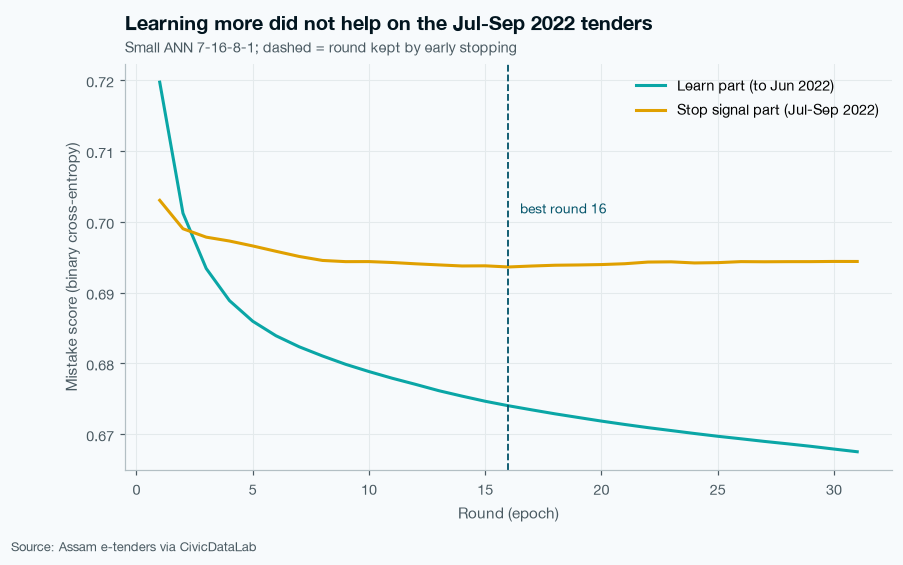

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.8))  # one chart
rounds = np.arange(1, len(learn_loss) + 1)  # round numbers 1, 2, 3 ...
ax.plot(rounds, learn_loss, color=ts.MULTI, label="Learn part (to Jun 2022)")  # learn mistake score
ax.plot(rounds, stop_loss, color=ts.SINGLE, label="Stop signal part (Jul-Sep 2022)")  # stop signal mistake score
ax.axvline(best_round, color=ts.THIRD, linestyle="--", linewidth=1.2)  # the round I keep
ax.text(best_round + 0.5, max(stop_loss), "best round " + str(best_round), color=ts.THIRD, fontsize=9, va="top")  # name the dashed line

# labels and finish
ax.set_xlabel("Round (epoch)")  # x axis label
ax.set_ylabel("Mistake score (binary cross-entropy)")  # y axis label
ax.legend(loc="upper right")  # legend
subtitle = "Small ANN 7-16-8-1; dashed = round kept by early stopping"  # what is measured
ts.title(ax, "Learning more did not help on the Jul-Sep 2022 tenders", subtitle=subtitle)  # the finding
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9a_learning_curve.png")  # save the chart

### Step 8 · Try a few sizes, with and without dropout

I did not want to guess the size of the network, so I try four versions. I pick the winner using only the stop signal part, so validation stays untouched.

Dropout is a trick against memorising. During learning, some helpers are told to "sit out" at random in every batch (here 20% of them), so no single helper can learn a tender by heart. When the network gives real scores, all helpers work.

| Version | Layers | Dropout |
|---|---|---|
| small | 16 then 8 helpers | no |
| medium | 32 then 16 helpers | no |
| small + dropout | 16 then 8 helpers | 20% sit out |
| medium + dropout | 32 then 16 helpers | 20% sit out |

First I put Steps 4 to 6 into small helpers, so I can repeat them for every version without copying code.

In [21]:
def build_ann(n_inputs, sizes, drop, seed):  # helper 1: build and compile a network
    keras.utils.set_random_seed(seed)  # fix the random start
    net = keras.Sequential()  # empty network
    net.add(keras.Input(shape=(n_inputs,)))  # the door for the clues
    for size in sizes:  # one hidden layer for each size in the list
        net.add(keras.layers.Dense(size, activation="relu"))  # a layer of helpers
        if drop > 0:  # only when dropout is switched on
            net.add(keras.layers.Dropout(drop))  # some helpers sit out during learning
    net.add(keras.layers.Dense(1, activation="sigmoid"))  # the answer between 0 and 1
    net.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="binary_crossentropy")  # teacher and mistake score
    return net  # give back the network

In [22]:
def make_weights(y):  # helper 2: balanced class weights as a dictionary
    w = compute_class_weight("balanced", classes=np.array([0, 1]), y=y)  # weights for 0 and 1
    cw = {}  # empty dictionary
    cw[0] = w[0]  # weight for more than one bid
    cw[1] = w[1]  # weight for one bid
    return cw  # give back the weights

In [23]:
def train_with_stop(x_l, y_l, x_s, y_s, sizes, drop, seed):  # helper 3: train with early stopping on the stop signal part
    net = build_ann(x_l.shape[1], sizes, drop, seed)  # a fresh network
    cw_s = make_weights(y_s)  # balanced weights for the stop signal part
    w_s = np.where(y_s == 1, cw_s[1], cw_s[0])  # one weight per stop signal tender
    rule = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)  # early stopping rule
    hist = net.fit(x_l, y_l, validation_data=(x_s, y_s, w_s), epochs=300, batch_size=32, class_weight=make_weights(y_l), callbacks=[rule], verbose=0)  # train
    best = int(np.argmin(hist.history["val_loss"])) + 1  # best round
    return net, hist, best  # give back the network, its history and the best round

In [24]:
def ann_risk(net, x):  # helper 4: risk scores from a network as a plain list of numbers
    return net.predict(x, verbose=0).ravel()  # one score per tender

A quick check: the helpers must give exactly the same result as my step-by-step network from Steps 4 to 6.

In [25]:
check_net, check_hist, check_best = train_with_stop(x_learn, y_learn, x_stop, y_stop, [16, 8], 0.0, 42)  # same small network with the helpers
check_gap = np.abs(ann_risk(check_net, x_stop) - risk_stop).max()  # biggest difference in scores
print("Best round with helpers:", check_best, "| step by step:", best_round)  # should be the same
print("Biggest score difference:", round(float(check_gap), 6))  # 0.0 = same

Best round with helpers: 16 | step by step: 16
Biggest score difference: 0.0


In [26]:
versions = []  # the four versions to try
versions.append(["small", [16, 8], 0.0])  # 16 then 8 helpers, no dropout
versions.append(["medium", [32, 16], 0.0])  # 32 then 16 helpers, no dropout
versions.append(["small + dropout", [16, 8], 0.2])  # small with 20% dropout
versions.append(["medium + dropout", [32, 16], 0.2])  # medium with 20% dropout

In [27]:
size_rows = []  # one result row per version
size_curves = {}  # stop signal mistake score per round, for the chart
for v in versions:  # train every version
    net, hist, best = train_with_stop(x_learn, y_learn, x_stop, y_stop, v[1], v[2], 42)  # train with early stopping
    row = {}  # empty row
    row["version"] = v[0]  # version name
    row["best round"] = best  # round kept
    row["stop mistake score"] = round(min(hist.history["val_loss"]), 4)  # smallest stop signal mistake
    row["stop PR-AUC"] = round(average_precision_score(y_stop, ann_risk(net, x_stop)), 3)  # PR-AUC on the stop signal part
    row["numbers learned"] = net.count_params()  # size of the network
    size_rows.append(row)  # add the row
    size_curves[v[0]] = hist.history["val_loss"]  # keep the curve

I also put LogReg on the same learn part and score it on the stop signal part, so I know where the checklist stands on this small check.

In [28]:
lr_check = LogisticRegression(class_weight="balanced", max_iter=3000)  # LogReg, same settings as S5 and S7
lr_check.fit(x_learn, y_learn)  # learn from the learn part
lr_stop_pr = average_precision_score(y_stop, lr_check.predict_proba(x_stop)[:, 1])  # PR-AUC on the stop signal part
row = {}  # one more row for LogReg
row["version"] = "LogReg (for comparison)"  # name
row["best round"] = np.nan  # LogReg has no rounds
row["stop mistake score"] = np.nan  # not the same kind of mistake score
row["stop PR-AUC"] = round(lr_stop_pr, 3)  # PR-AUC on the stop signal part
row["numbers learned"] = len(base) + 1  # 7 weights + 1 starting number
size_rows.append(row)  # add the row
size_table = pd.DataFrame(size_rows)  # the size try table
size_table.to_csv(rep_dir + "/s9_size_try.csv", index=False)  # save it
size_table  # show it

,version,best round,stop mistake score,stop PR-AUC,numbers learned
0,small,16.0,0.6936,0.361,273
1,medium,2.0,0.6901,0.377,801
2,small + dropout,12.0,0.6898,0.360,273
3,medium + dropout,20.0,0.6872,0.357,801
4,LogReg (for comparison),NaN,NaN,0.360,8


I pick the version with the best PR-AUC on the stop signal part. PR-AUC is the score I care about most (how well single-bid tenders come to the top of the list), so I choose with it, not with the mistake score.

In [29]:
ann_only = size_table[size_table["version"] != "LogReg (for comparison)"]  # only the four ANN versions
pick = ann_only.sort_values("stop PR-AUC", ascending=False).iloc[0]  # the version with the best stop signal PR-AUC
pick_name = pick["version"]  # its name
pick_round = int(pick["best round"])  # its best round
for v in versions:  # find its layers and dropout
    if v[0] == pick_name:  # this is the chosen version
        pick_sizes = v[1]  # its layer sizes
        pick_drop = v[2]  # its dropout
print("Chosen version:", pick_name, "| layers:", pick_sizes, "| dropout:", pick_drop, "| best round:", pick_round)  # the choice

Chosen version: medium | layers: [32, 16] | dropout: 0.0 | best round: 2


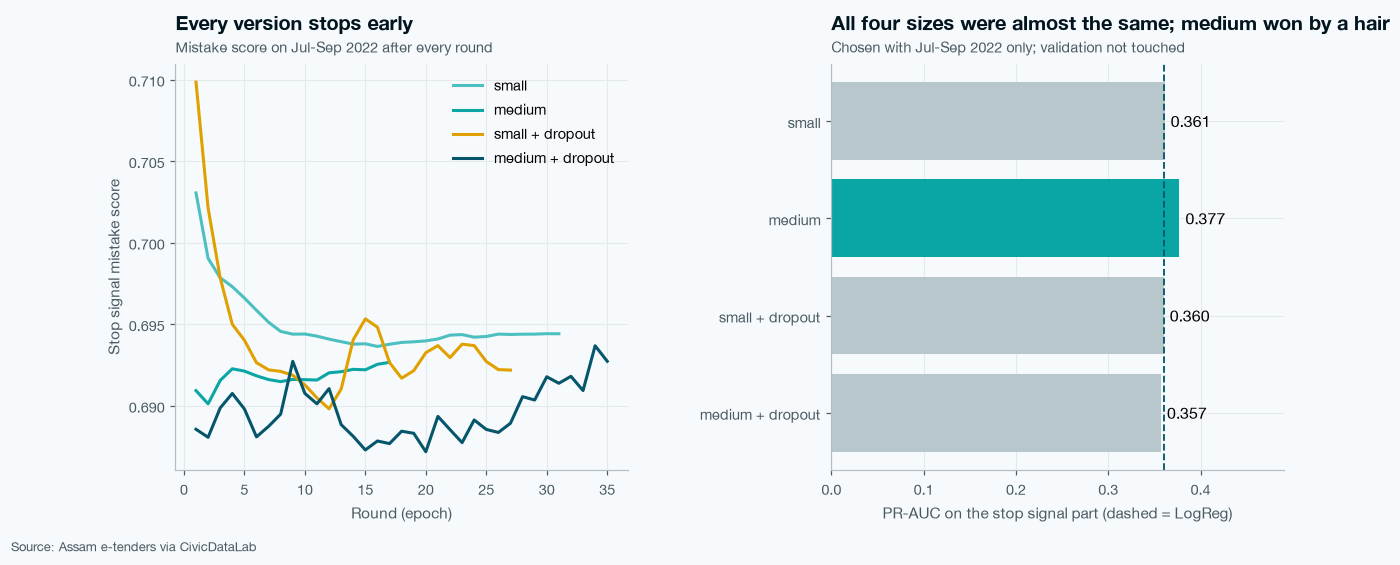

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))  # two charts side by side
curve_colors = [ts.BLUES[2], ts.BLUES[3], ts.SINGLE, ts.THIRD]  # one colour per version
for i, name in enumerate(size_curves):  # one line per version
    axes[0].plot(np.arange(1, len(size_curves[name]) + 1), size_curves[name], color=curve_colors[i], label=name)  # stop signal mistake per round
axes[0].set_xlabel("Round (epoch)")  # x axis label
axes[0].set_ylabel("Stop signal mistake score")  # y axis label
axes[0].legend(loc="upper right")  # legend
ts.title(axes[0], "Every version stops early", subtitle="Mistake score on Jul-Sep 2022 after every round")  # left title

# right: stop signal PR-AUC per version, LogReg as the dashed reference
show = ann_only  # the four ANN versions
bar_colors = np.where(show["version"] == pick_name, ts.MULTI, ts.NEUTRAL)  # chosen version in teal
bars = axes[1].barh(show["version"], show["stop PR-AUC"], color=bar_colors)  # one bar per version
axes[1].bar_label(bars, fmt="%.3f", padding=4)  # numbers on bars
axes[1].axvline(lr_stop_pr, color=ts.THIRD, linestyle="--", linewidth=1.2)  # LogReg on the same check
axes[1].invert_yaxis()  # first version on top
axes[1].set_xlim(0, max(show["stop PR-AUC"].max(), lr_stop_pr) * 1.3)  # room for labels
axes[1].set_xlabel("PR-AUC on the stop signal part (dashed = LogReg)")  # x axis label
subtitle = "Chosen with Jul-Sep 2022 only; validation not touched"  # what is measured
ts.title(axes[1], "All four sizes were almost the same; medium won by a hair", subtitle=subtitle)  # right title
fig.subplots_adjust(wspace=0.45)  # space between the two charts
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9b_size_try.png")  # save the chart

### Insight · Steps 3 to 8 (learning, stopping and size)

- I cut training into a learn part (up to Jun 2022, 1,769 tenders, 37.6% single-bid) and a stop signal part (Jul-Sep 2022, 984 tenders, 33.2% single-bid). Validation was not touched while the network learned.
- My first small network (7 -> 16 -> 8 -> 1) has 273 numbers to learn. LogReg on the same 7 clues has only 8.
- The class weights were 0.802 for "more than one bid" and 1.328 for "one bid", so mistakes on single-bid tenders counted about 1.7 times more.
- The learning curve tells the main story. The learn line kept going down, but the stop signal line went flat at about 0.694 and stayed there. 0.693 is the mistake score of pure guessing (50/50). So whatever the network learned up to Jun 2022 hardly helped on Jul-Sep 2022 tenders. This is the same drift I found in S5, now seen inside the training months.
- Early stopping kept round 16 for the small network. My helpers gave exactly the same result as the step-by-step version (difference 0.0), so the helpers are correct.
- All four sizes were almost the same on the stop signal part: small 0.361, medium 0.377, small + dropout 0.360, medium + dropout 0.357. LogReg got 0.360 on the same check.
- The medium network won by a small margin, but it kept only round 2. That means it was stopped very early, before it had learned much. I followed my rule and used it, but this already warned me that the network would stay close to random.

### Step 9 · Retrain the chosen network on all training months

The stop signal part told me how many rounds to use. But the Jul-Sep 2022 tenders are the newest and most useful training tenders, so I do not want to leave them out of the final network. Now I train the chosen network again on all training months (to Sep 2022) for exactly that number of rounds, with no early stopping.

This is the same data that LogReg used in S5 (all training tenders, scored on validation), so the race is like-for-like. The scaler now learns from all training tenders too.

One honest note: like LogReg in S6, about 254 September training tenders had their bids opened in October. This is tiny, and I keep it the same for both models so the race stays fair.

In [31]:
scaler_tr = StandardScaler()  # a new scaler
scaler_tr.fit(train[base])  # learn clue sizes from all training tenders
x_train = scaler_tr.transform(train[base])  # scaled training clues
x_val = scaler_tr.transform(val[base])  # scaled validation clues (same sizes as training)
y_train = train["single_bid"].values  # training answers
y_val = val["single_bid"].values  # validation answers

In [32]:
def train_full(x, y, sizes, drop, rounds, seed):  # helper 5: train on all given tenders for a fixed number of rounds
    net = build_ann(x.shape[1], sizes, drop, seed)  # a fresh network
    net.fit(x, y, epochs=rounds, batch_size=32, class_weight=make_weights(y), verbose=0)  # train, no early stopping
    return net  # give back the network

In [33]:
ann = train_full(x_train, y_train, pick_sizes, pick_drop, pick_round, 42)  # the final ANN, learned on all training months
val["risk_ann"] = ann_risk(ann, x_val)  # ANN risk score for every validation tender
val["risk_ann"].describe().round(3)  # quick look at the scores

count    2270.000
mean        0.493
std         0.072
min         0.169
25%         0.459
50%         0.512
75%         0.539
max         0.729
Name: risk_ann, dtype: float64

In [34]:
lr = LogisticRegression(class_weight="balanced", max_iter=3000)  # LogReg, same settings as S5 and S7
lr.fit(x_train, y_train)  # learn from all training tenders
val["risk_lr"] = lr.predict_proba(x_val)[:, 1]  # LogReg risk score for every validation tender

## Part C · The fair race on validation

### Step 10 · ANN vs LogReg vs Rule B vs random checking

Now I open the validation answers for the race. I use the same benchmarks as S5: random checking (seed 42) and Rule B (quick re-tenders first, then the department's past single-bid rate). I also use the same scores as S7.

| Score | What it means |
|---|---|
| PR-AUC | how well a method puts single-bid tenders at the top of the list (random gets about the single-bid rate) |
| ROC-AUC | 0.5 = no better than tossing a coin, 1.0 = perfect order |
| capture top 20% | if the auditor checks the riskiest 20%, how many of all single-bid tenders she finds (random = 20%) |
| lift top 20% | capture divided by 20. 1.0 = same as random |
| precision top 100 | out of the 100 riskiest tenders, how many really got one bid |

In [35]:
rng = np.random.default_rng(42)  # same seed as S5 and S6
val["risk_random"] = rng.random(len(val))  # random checking: every tender gets a random score
val["risk_ruleb"] = val["retender_60d"] + val["dept_rate"] / 10  # Rule B: re-tender first, department rate breaks ties
val_rate = y_val.mean() * 100  # validation single-bid rate
print("Validation tenders:", len(val), "| single-bid:", int(y_val.sum()), "| rate:", round(val_rate, 1), "%")  # the race track

Validation tenders: 2270 | single-bid: 630 | rate: 27.8 %


In [36]:
def capture(y, risk, share):  # helper 6: share (%) of all single-bid tenders found in the riskiest top part
    t = pd.DataFrame({"real": np.asarray(y), "risk": np.asarray(risk)})  # answers and scores side by side
    t = t.sort_values("risk", ascending=False, kind="stable")  # riskiest first
    top = t.head(int(len(t) * share))  # the top part
    return top["real"].sum() / t["real"].sum() * 100  # found divided by all single-bid tenders

In [37]:
def precision_top(y, risk, k):  # helper 7: share (%) of real single-bid tenders among the k riskiest
    t = pd.DataFrame({"real": np.asarray(y), "risk": np.asarray(risk)})  # answers and scores side by side
    t = t.sort_values("risk", ascending=False, kind="stable")  # riskiest first
    return t.head(k)["real"].mean() * 100  # share of real single-bid tenders

In [38]:
def score_row(name, y, risk):  # helper 8: all scores for one method as one row
    row = {}  # empty row
    row["method"] = name  # method name
    row["PR-AUC"] = round(average_precision_score(y, risk), 3)  # PR-AUC
    row["ROC-AUC"] = round(roc_auc_score(y, risk), 3)  # ROC-AUC
    row["capture top 10%"] = round(capture(y, risk, 0.1), 1)  # found in the riskiest 10%
    row["capture top 20%"] = round(capture(y, risk, 0.2), 1)  # found in the riskiest 20%
    row["capture top 30%"] = round(capture(y, risk, 0.3), 1)  # found in the riskiest 30%
    row["lift top 20%"] = round(capture(y, risk, 0.2) / 20, 2)  # times better than random at 20%
    row["precision top 50"] = round(precision_top(y, risk, 50), 1)  # real single-bid among the 50 riskiest
    row["precision top 100"] = round(precision_top(y, risk, 100), 1)  # among the 100 riskiest
    row["precision top 200"] = round(precision_top(y, risk, 200), 1)  # among the 200 riskiest
    return row  # give back the row

In [39]:
methods = {}  # risk column -> name (one line each)
methods["risk_random"] = "Random checking"  # benchmark 1
methods["risk_ruleb"] = "Rule B: re-tender then dept"  # benchmark 2
methods["risk_lr"] = "LogReg 7 clues"  # the checklist model
methods["risk_ann"] = "ANN 7 clues"  # the new network

In [40]:
race = []  # one row per method
for col in methods:  # score every method
    race.append(score_row(methods[col], y_val, val[col].values))  # add its row

In [41]:
rng500 = np.random.default_rng(7)  # random is luck, so also average 500 random draws (same as S7)
draw_rows = []  # one row per draw
for i in range(500):  # 500 random draws
    draw_rows.append(score_row("draw", y_val, rng500.random(len(val))))  # score one random draw
draws = pd.DataFrame(draw_rows)  # all draws as a table
random_avg = draws.drop(columns="method").mean().round(3)  # the average of the 500 draws
avg_row = {}  # one more row
avg_row["method"] = "Random (average of 500 draws)"  # name
avg_row.update(random_avg.to_dict())  # add the average scores
race.append(avg_row)  # add the row
race_table = pd.DataFrame(race)  # the race table
race_table  # show it

,method,PR-AUC,ROC-AUC,capture top 10%,capture top 20%,capture top 30%,lift top 20%,precision top 50,precision top 100,precision top 200
0,Random checking,0.288,0.514,11.100,19.800,30.200,0.990,38.000,32.000,30.500
1,Rule B: re-tender then dept,0.268,0.431,12.500,14.600,17.000,0.730,60.000,52.000,39.500
2,LogReg 7 clues,0.252,0.426,9.000,11.700,18.600,0.590,42.000,33.000,27.500
3,ANN 7 clues,0.286,0.475,11.600,22.900,31.600,1.140,38.000,33.000,33.000
4,Random (average of 500 draws),0.280,0.500,9.942,19.983,29.949,0.999,27.368,27.468,27.605


In [42]:
random_pr = random_avg["PR-AUC"]  # the dashed line for PR-AUC charts
ann_pr = race_table.loc[race_table["method"] == "ANN 7 clues", "PR-AUC"].iloc[0]  # ANN PR-AUC
lr_pr = race_table.loc[race_table["method"] == "LogReg 7 clues", "PR-AUC"].iloc[0]  # LogReg PR-AUC
print("Random average PR-AUC:", random_pr, "| LogReg:", lr_pr, "| ANN:", ann_pr)  # the main three numbers

Random average PR-AUC: 0.28 | LogReg: 0.252 | ANN: 0.286


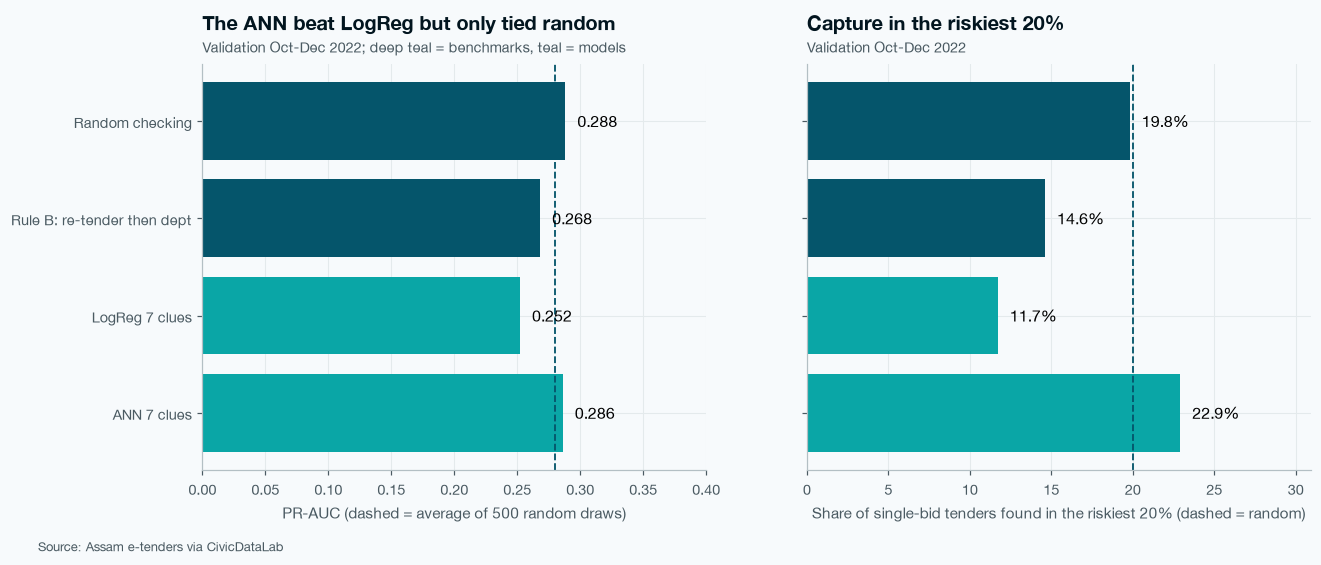

In [43]:
show = race_table.iloc[:4]  # the 4 methods (not the 500-draw average)
benchmarks = ["Random checking", "Rule B: re-tender then dept"]  # benchmark names
colors = np.where(show["method"].isin(benchmarks), ts.THIRD, ts.MULTI)  # benchmarks deep teal, models teal
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)  # two charts side by side

# left: PR-AUC with the random line
b1 = axes[0].barh(show["method"], show["PR-AUC"], color=colors)  # one bar per method
axes[0].bar_label(b1, fmt="%.3f", padding=8)  # numbers on bars
axes[0].axvline(random_pr, color=ts.THIRD, linestyle="--", linewidth=1.2)  # random average line
axes[0].set_xlim(0, max(show["PR-AUC"].max() * 1.35, 0.4))  # room for labels
axes[0].invert_yaxis()  # first method on top
axes[0].set_xlabel("PR-AUC (dashed = average of 500 random draws)")  # x axis label
subtitle = "Validation Oct-Dec 2022; deep teal = benchmarks, teal = models"  # what is measured
ts.title(axes[0], "The ANN beat LogReg but only tied random", subtitle=subtitle)  # left title

# right: capture in the riskiest 20% with the random 20% line
b2 = axes[1].barh(show["method"], show["capture top 20%"], color=colors)  # one bar per method
axes[1].bar_label(b2, fmt="%.1f%%", padding=8)  # numbers on bars
axes[1].axvline(20, color=ts.THIRD, linestyle="--", linewidth=1.2)  # random finds 20%
axes[1].set_xlim(0, max(show["capture top 20%"].max() * 1.35, 30))  # room for labels
axes[1].set_xlabel("Share of single-bid tenders found in the riskiest 20% (dashed = random)")  # x axis label
ts.title(axes[1], "Capture in the riskiest 20%", subtitle="Validation Oct-Dec 2022")  # right title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9c_validation_race.png")  # save the chart

### Insight · The fair race on validation (Steps 9 and 10)

- Validation has 2,270 tenders and 630 single-bid tenders (27.8%).
- PR-AUC: random checking 0.288, Rule B 0.268, LogReg 0.252 and the ANN 0.286. The average of 500 random draws is 0.280.
- So the ANN did better than LogReg and Rule B, but it was not better than random checking. It was only level with it.
- The ANN found 22.9% of the single-bid tenders in its riskiest 20% (lift 1.14), while LogReg found only 11.7% and Rule B 14.6%.
- ROC-AUC tells me the same thing in another way. The ANN got 0.475, which is a little below coin toss (0.5). LogReg got 0.426, which means its order was more upside down.
- LogReg on full training gave exactly the S5 number (0.252), so the race used the same data as before.

### Step 11 · Seed check: is the ANN result just luck of the starting point?

A network starts from random numbers. A different seed (starting point) can give a different result, and small networks on small data can wobble a lot. So I train the same final network with 5 more seeds and look at the range. If the range is wide, one single run should not be trusted.

In [44]:
seed_rows = []  # one row per seed
seed_risks = {}  # validation scores per seed (for later checks)
for seed in [1, 2, 3, 4, 5]:  # five other starting points
    net = train_full(x_train, y_train, pick_sizes, pick_drop, pick_round, seed)  # same network, different start
    risk = ann_risk(net, x_val)  # validation scores
    seed_risks[seed] = risk  # keep the scores
    seed_rows.append(score_row("ANN seed " + str(seed), y_val, risk))  # score this seed
seed_rows.append(score_row("ANN seed 42 (main)", y_val, val["risk_ann"].values))  # the main seed too
seed_table = pd.DataFrame(seed_rows)[["method", "PR-AUC", "ROC-AUC", "capture top 20%"]]  # keep the main scores
seed_table.to_csv(rep_dir + "/s9_seed_check.csv", index=False)  # save it
seed_table  # show it

,method,PR-AUC,ROC-AUC,capture top 20%
0,ANN seed 1,0.250,0.437,15.4
1,ANN seed 2,0.264,0.439,18.9
2,ANN seed 3,0.265,0.443,18.9
3,ANN seed 4,0.231,0.403,11.9
4,ANN seed 5,0.293,0.484,22.4
5,ANN seed 42 (main),0.286,0.475,22.9


In [45]:
seed_low = seed_table["PR-AUC"].min()  # lowest PR-AUC over the 6 seeds
seed_high = seed_table["PR-AUC"].max()  # highest PR-AUC
seed_mean = seed_table["PR-AUC"].mean()  # average PR-AUC
seeds_above_random = int((seed_table["PR-AUC"] > random_pr).sum())  # seeds that beat the random average
print("PR-AUC range:", seed_low, "to", seed_high, "| average:", round(seed_mean, 3))  # how much it wobbles
print("Seeds above the random average:", seeds_above_random, "of", len(seed_table))  # how many beat random

PR-AUC range: 0.231 to 0.293 | average: 0.265
Seeds above the random average: 2 of 6


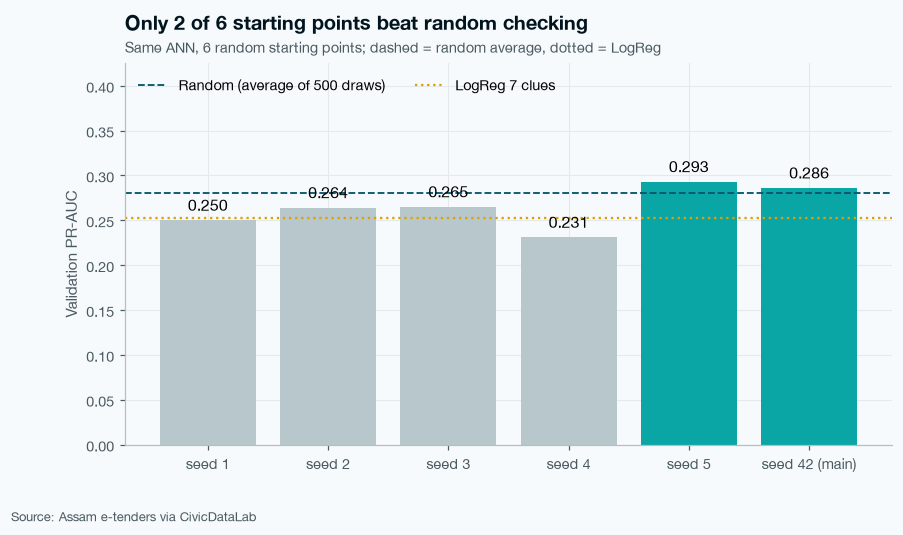

In [46]:
fig, ax = plt.subplots(figsize=(9, 4.5))  # one chart
bar_colors = np.where(seed_table["PR-AUC"] > random_pr, ts.MULTI, ts.NEUTRAL)  # teal = above random, grey = not
bars = ax.bar(seed_table["method"].str.replace("ANN ", ""), seed_table["PR-AUC"], color=bar_colors)  # one bar per seed
ax.bar_label(bars, fmt="%.3f", padding=4)  # numbers on bars
ax.axhline(random_pr, color=ts.THIRD, linestyle="--", linewidth=1.2, label="Random (average of 500 draws)")  # random average
ax.axhline(lr_pr, color=ts.SINGLE, linestyle=":", linewidth=1.5, label="LogReg 7 clues")  # LogReg
ax.set_ylim(0, max(seed_table["PR-AUC"].max(), random_pr) * 1.45)  # headroom for the legend
ax.legend(loc="upper left", ncol=2)  # legend for the two lines
ax.set_ylabel("Validation PR-AUC")  # y axis label
subtitle = "Same ANN, 6 random starting points; dashed = random average, dotted = LogReg"  # what is measured
ts.title(ax, "Only 2 of 6 starting points beat random checking", subtitle=subtitle)  # the finding
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9d_seed_check.png")  # save the chart

### Insight · Seed check (Step 11)

- I trained the same network with 6 different random starting points. PR-AUC went from 0.231 to 0.293 (average 0.265).
- Only 2 of the 6 seeds (seed 5 with 0.293 and my main seed 42 with 0.286) were above the random average of 0.280. The other 4 were below it.
- A gap of 0.06 just from changing the starting point is big compared to the gaps between methods. So the 0.286 of my main run was partly luck of the start.
- This is a common weak point of neural networks on small data: one run is not enough to trust.

### Step 12 · A simple team-up: average of ANN and LogReg ranks

Mixing two models sometimes helps, because each one fixes some of the other's mistakes. The simplest fair mix is to rank the tenders by each model and take the average rank. I use ranks and not scores, because the two models give scores on different scales.

Because I am trying this idea on validation, I call it a candidate only. It would need a fresh fair test before I could claim it works.

In [47]:
rank_ann = val["risk_ann"].rank(pct=True)  # ANN rank as a share (riskiest = close to 1)
rank_lr = val["risk_lr"].rank(pct=True)  # LogReg rank as a share
val["risk_team"] = (rank_ann + rank_lr) / 2  # the average rank = the team-up score
team_row = score_row("Team-up: ANN + LogReg (candidate)", y_val, val["risk_team"].values)  # score it
methods["risk_team"] = "Team-up: ANN + LogReg (candidate)"  # add it to the methods list
race_table = pd.concat([race_table, pd.DataFrame([team_row])], ignore_index=True)  # add its row to the race table
race_table[["method", "PR-AUC", "ROC-AUC", "capture top 20%"]]  # show the main scores

,method,PR-AUC,ROC-AUC,capture top 20%
0,Random checking,0.288,0.514,19.800
1,Rule B: re-tender then dept,0.268,0.431,14.600
2,LogReg 7 clues,0.252,0.426,11.700
3,ANN 7 clues,0.286,0.475,22.900
4,Random (average of 500 draws),0.280,0.500,19.983
5,Team-up: ANN + LogReg (candidate),0.253,0.443,16.200


### Step 13 · Bootstrap: is any difference real or just luck?

Same check as S5 and S7. I make 500 new validation sets by picking tenders at random (the same tender can be picked more than once), and score both methods on each one. If method A beats method B in 95% or more of the 500 sets, I call the win real.

In [48]:
def bootstrap(col_a, col_b):  # helper 9: 500 re-draws; PR-AUC of A minus PR-AUC of B in each
    rng_b = np.random.default_rng(42)  # same seed every time, so every pair sees the same 500 sets
    y_arr = val["single_bid"].values  # answers
    a = val[col_a].values  # scores of method A
    b = val[col_b].values  # scores of method B
    gaps = []  # empty list for the gaps
    for i in range(500):  # 500 re-draws
        pick_rows = rng_b.integers(0, len(val), len(val))  # pick tenders at random
        gaps.append(average_precision_score(y_arr[pick_rows], a[pick_rows]) - average_precision_score(y_arr[pick_rows], b[pick_rows]))  # the gap in this re-draw
    return np.array(gaps)  # give back all 500 gaps

In [49]:
def boot_row(name, gaps):  # helper 10: one table row for one pair
    row = {}  # empty row
    row["comparison"] = name  # pair name
    row["A wins (% of draws)"] = round((gaps > 0).mean() * 100, 1)  # how often A is better
    row["gap low (2.5%)"] = round(np.percentile(gaps, 2.5), 3)  # low end of the middle 95%
    row["gap high (97.5%)"] = round(np.percentile(gaps, 97.5), 3)  # high end of the middle 95%
    return row  # give back the row

In [50]:
pairs = []  # the pairs I compare (A, B, name)
pairs.append(["risk_ann", "risk_random", "ANN vs Random"])  # pair 1
pairs.append(["risk_ann", "risk_lr", "ANN vs LogReg"])  # pair 2
pairs.append(["risk_ann", "risk_ruleb", "ANN vs Rule B"])  # pair 3
pairs.append(["risk_team", "risk_random", "Team-up vs Random"])  # pair 4
boot_rows = []  # one row per pair
boot_gaps = {}  # the 500 gaps per pair, for the chart
for p in pairs:  # run every pair
    gaps = bootstrap(p[0], p[1])  # 500 gaps
    boot_gaps[p[2]] = gaps  # keep them
    boot_rows.append(boot_row(p[2], gaps))  # add the row
boot_table = pd.DataFrame(boot_rows)  # the bootstrap table
boot_table.to_csv(rep_dir + "/s9_bootstrap.csv", index=False)  # save it
boot_table  # show it

,comparison,A wins (% of draws),gap low (2.5%),gap high (97.5%)
0,ANN vs Random,43.0,-0.031,0.027
1,ANN vs LogReg,99.8,0.006,0.061
2,ANN vs Rule B,88.0,-0.013,0.046
3,Team-up vs Random,0.0,-0.061,-0.010


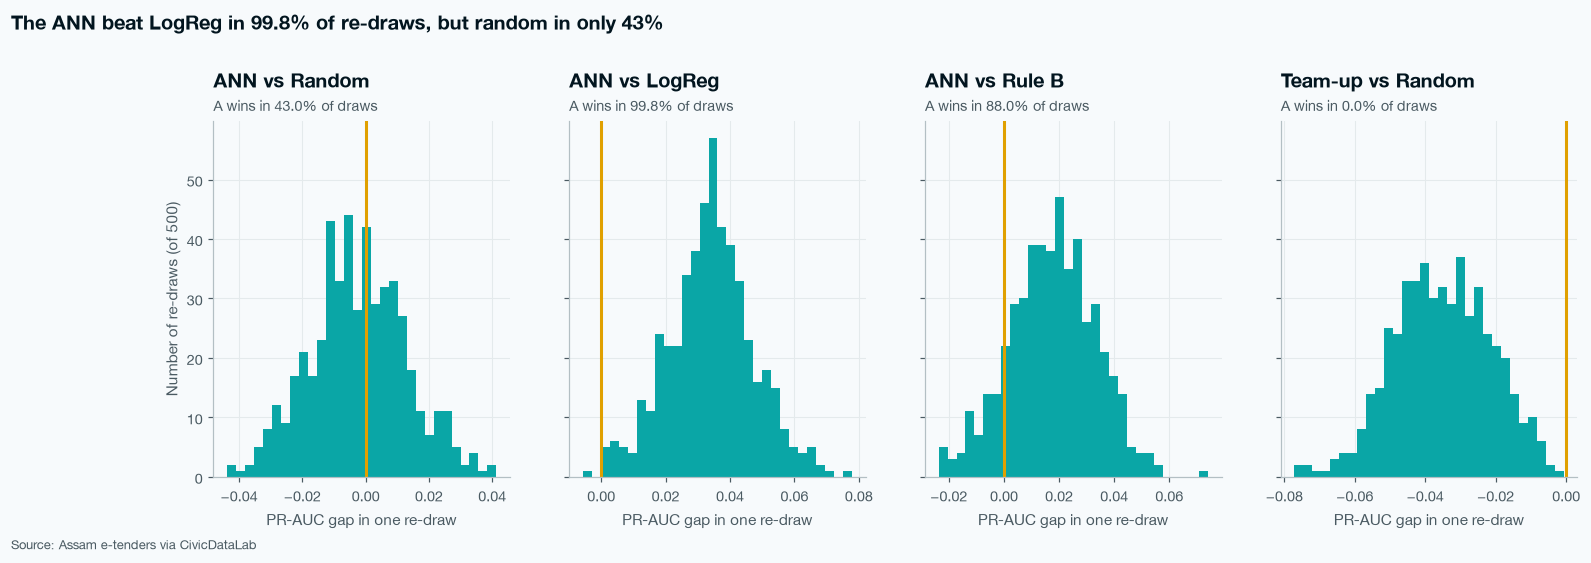

In [51]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)  # four small charts
for i, name in enumerate(boot_gaps):  # one chart per pair
    axes[i].hist(boot_gaps[name], bins=30, color=ts.BLUES[3])  # the 500 gaps
    axes[i].axvline(0, color=ts.SINGLE, linewidth=2)  # zero line: right of it = A is better
    axes[i].set_xlabel("PR-AUC gap in one re-draw")  # x axis label
    win_text = "A wins in " + str(boot_rows[i]["A wins (% of draws)"]) + "% of draws"  # subtitle text
    ts.title(axes[i], name, subtitle=win_text)  # title per chart
axes[0].set_ylabel("Number of re-draws (of 500)")  # y axis label on the first chart
fig.suptitle("The ANN beat LogReg in 99.8% of re-draws, but random in only 43%", x=0.01, ha="left", y=1.12, fontsize=13, fontweight="bold", color=ts.INK)  # one finding for the whole row
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9e_bootstrap.png")  # save the chart

### Insight · Team-up and bootstrap (Steps 12 and 13)

- The team-up (average of ANN and LogReg ranks) got 0.253. It did not help, because LogReg pulled it down.
- Bootstrap results (500 re-draws):
  - ANN vs random: the ANN won in only 43.0% of the draws. That is basically a coin toss, so the ANN is not better than random checking.
  - ANN vs LogReg: the ANN won in 99.8%. This looks like a strong win, but LogReg itself was below random on validation, so beating it is not enough.
  - ANN vs Rule B: 88.0%, not enough to call it real.
  - Team-up vs random: 0.0%, so the team-up was clearly worse than random.
- The honest reading: the ANN only looked good next to a model that drift had turned upside down.

### Step 14 · Month by month (Oct, Nov, Dec 2022)

December 2022 was very different (a big road-work wave with few single bids, from S3 and S6). So I check each validation month on its own. A few validation tenders are dated before October (they share a reference number with a later tender, from S4), so they go with October, the same way as in S5 and S6.

In [52]:
val["score_month"] = val["published_date"].dt.to_period("M").astype(str)  # year-month as text, like "2022-10"
early = val["published_date"] < "2022-10-01"  # validation tenders dated before October
val.loc[early, "score_month"] = "2022-10"  # they go with October
month_names = {}  # friendly month names
month_names["2022-10"] = "Oct 2022"  # October
month_names["2022-11"] = "Nov 2022"  # November
month_names["2022-12"] = "Dec 2022"  # December
val["month_name"] = val["score_month"].map(month_names)  # month name column
month_order = ["Oct 2022", "Nov 2022", "Dec 2022"]  # time order
print("Validation tenders dated before October (go with October):", int(early.sum()))  # about 59
val["month_name"].value_counts().reindex(month_order)  # tenders per month

Validation tenders dated before October (go with October): 59


month_name
Oct 2022     317
Nov 2022     732
Dec 2022    1221
Name: count, dtype: int64

In [53]:
def month_row(name):  # helper 11: single-bid rate and capture top 20% of every method for one month
    part = val[val["month_name"] == name]  # tenders of this month
    row = {}  # empty row
    row["month"] = name  # month name
    row["tenders"] = len(part)  # number of tenders
    row["single-bid %"] = round(part["single_bid"].mean() * 100, 1)  # single-bid rate
    row["Random"] = round(capture(part["single_bid"], part["risk_random"], 0.2), 1)  # random
    row["Rule B"] = round(capture(part["single_bid"], part["risk_ruleb"], 0.2), 1)  # Rule B
    row["LogReg"] = round(capture(part["single_bid"], part["risk_lr"], 0.2), 1)  # LogReg
    row["ANN"] = round(capture(part["single_bid"], part["risk_ann"], 0.2), 1)  # ANN
    return row  # give back the row

In [54]:
month_rows = []  # one row per month
for name in month_order:  # every validation month
    month_rows.append(month_row(name))  # add its row
month_table = pd.DataFrame(month_rows)  # the month table
month_table.to_csv(rep_dir + "/s9_month_table.csv", index=False)  # save it
month_table  # show it

,month,tenders,single-bid %,Random,Rule B,LogReg,ANN
0,Oct 2022,317,36.6,20.7,23.3,19.8,17.2
1,Nov 2022,732,38.0,20.5,19.8,16.2,21.2
2,Dec 2022,1221,19.3,19.1,11.4,14.4,20.3


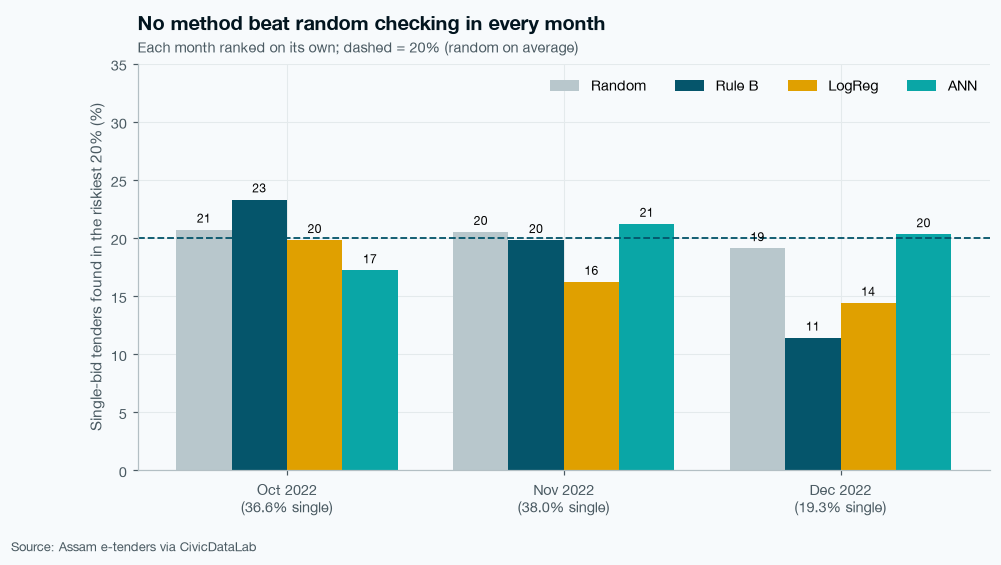

In [55]:
fig, ax = plt.subplots(figsize=(10, 4.8))  # one chart
pos = np.arange(len(month_table))  # one position per month
b1 = ax.bar(pos - 0.3, month_table["Random"], width=0.2, color=ts.NEUTRAL, label="Random")  # random
b2 = ax.bar(pos - 0.1, month_table["Rule B"], width=0.2, color=ts.THIRD, label="Rule B")  # Rule B
b3 = ax.bar(pos + 0.1, month_table["LogReg"], width=0.2, color=ts.SINGLE, label="LogReg")  # LogReg
b4 = ax.bar(pos + 0.3, month_table["ANN"], width=0.2, color=ts.MULTI, label="ANN")  # ANN
ax.bar_label(b1, fmt="%.0f", padding=3, fontsize=8)  # labels
ax.bar_label(b2, fmt="%.0f", padding=3, fontsize=8)  # labels
ax.bar_label(b3, fmt="%.0f", padding=3, fontsize=8)  # labels
ax.bar_label(b4, fmt="%.0f", padding=3, fontsize=8)  # labels
ax.axhline(20, color=ts.THIRD, linestyle="--", linewidth=1.2)  # random finds 20% on average
month_labels = []  # two-line tick labels: month and single-bid rate
for i in range(len(month_table)):  # one label per month
    month_labels.append(month_table["month"].iloc[i] + "\n(" + str(month_table["single-bid %"].iloc[i]) + "% single)")  # label text
ax.set_xticks(pos, month_labels)  # month names under the bars
ax.set_ylim(0, max(month_table[["Random", "Rule B", "LogReg", "ANN"]].max().max() * 1.3, 35))  # headroom
ax.set_ylabel("Single-bid tenders found in the riskiest 20% (%)")  # y axis label
ax.legend(loc="upper right", ncol=4)  # legend in one row
subtitle = "Each month ranked on its own; dashed = 20% (random on average)"  # what is measured
ts.title(ax, "No method beat random checking in every month", subtitle=subtitle)  # the finding
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9f_month_by_month.png")  # save the chart

### Insight · Month by month (Step 14)

- October had 317 tenders (36.6% single-bid), November 732 (38.0%) and December 1,221 (only 19.3%). 59 tenders dated before October went with October.
- In October the ANN was the weakest (17.2% found vs random 20.7%).
- In November (21.2%) and December (20.3%) the ANN was about the same as random (20.5% and 19.1%).
- Rule B and LogReg fell badly in December (11.4% and 14.4%). The ANN did not fall, but it also did not rise above random.
- So no method was steady across all three months. December, the big road-work month from S6, is still where the old clue patterns break the most.

### Step 15 · Auditor view: the riskiest 20%, across all months and inside each month

Here I play the auditor. She checks the riskiest 20% of validation tenders. For every method I count the single-bid tenders she finds and their value in crore (1 crore = 1,00,00,000 rupees).

I do it two ways. "Across all months" ranks all validation tenders together. "Inside each month" takes the riskiest 20% of every month on its own. S7 showed that months_to_fy_end can push whole months up or down, and the app will rank each month's tenders on their own. So the "inside each month" view is closer to how the app will really work.

In [56]:
n_check = int(len(val) * 0.2)  # how many tenders the auditor checks
all_single = int(y_val.sum())  # all single-bid tenders in validation
print("Checked:", n_check, "| all single-bid tenders in validation:", all_single)  # the scale

Checked: 454 | all single-bid tenders in validation: 630


In [57]:
def top20(col):  # helper 12: the riskiest 20% of all validation tenders
    t = val.sort_values(col, ascending=False, kind="stable")  # riskiest first
    return t.head(n_check)  # the top 20%

In [58]:
def top20_inside_month(col):  # helper 13: the riskiest 20% of every month, put together
    parts = []  # one piece per month
    for name in month_order:  # every month
        part = val[val["month_name"] == name].sort_values(col, ascending=False, kind="stable")  # riskiest first inside the month
        parts.append(part.head(int(len(part) * 0.2)))  # top 20% of this month
    return pd.concat(parts)  # all months together

In [59]:
auditor_rows = []  # one row per method
for col in methods:  # every method
    top = top20(col)  # riskiest 20% across all months
    caught = top[top["single_bid"] == 1]  # the single-bid tenders found
    top_m = top20_inside_month(col)  # riskiest 20% inside each month
    row = {}  # empty row
    row["method"] = methods[col]  # name
    row["caught (all months)"] = len(caught)  # found across all months
    row["Rs crore caught"] = round(caught["estimated_value"].sum() / 1e7, 1)  # their value
    row["caught (inside each month)"] = int(top_m["single_bid"].sum())  # found inside each month
    row["checked inside each month"] = len(top_m)  # tenders checked that way (a few less because of rounding)
    auditor_rows.append(row)  # add the row
auditor = pd.DataFrame(auditor_rows)  # the auditor table
auditor.to_csv(rep_dir + "/s9_auditor_view.csv", index=False)  # save it
auditor  # show it

,method,caught (all months),Rs crore caught,caught (inside each month),checked inside each month
0,Random checking,125,233.1,126,453
1,Rule B: re-tender then dept,92,425.9,109,453
2,LogReg 7 clues,74,398.5,102,453
3,ANN 7 clues,144,106.1,127,453
4,Team-up: ANN + LogReg (candidate),102,163.6,105,453


In [60]:
total_crore = val.loc[val["single_bid"] == 1, "estimated_value"].sum() / 1e7  # all single-bid value in validation
print("Value of all single-bid validation tenders: Rs", round(total_crore, 1), "crore")  # for scale

Value of all single-bid validation tenders: Rs 1316.2 crore


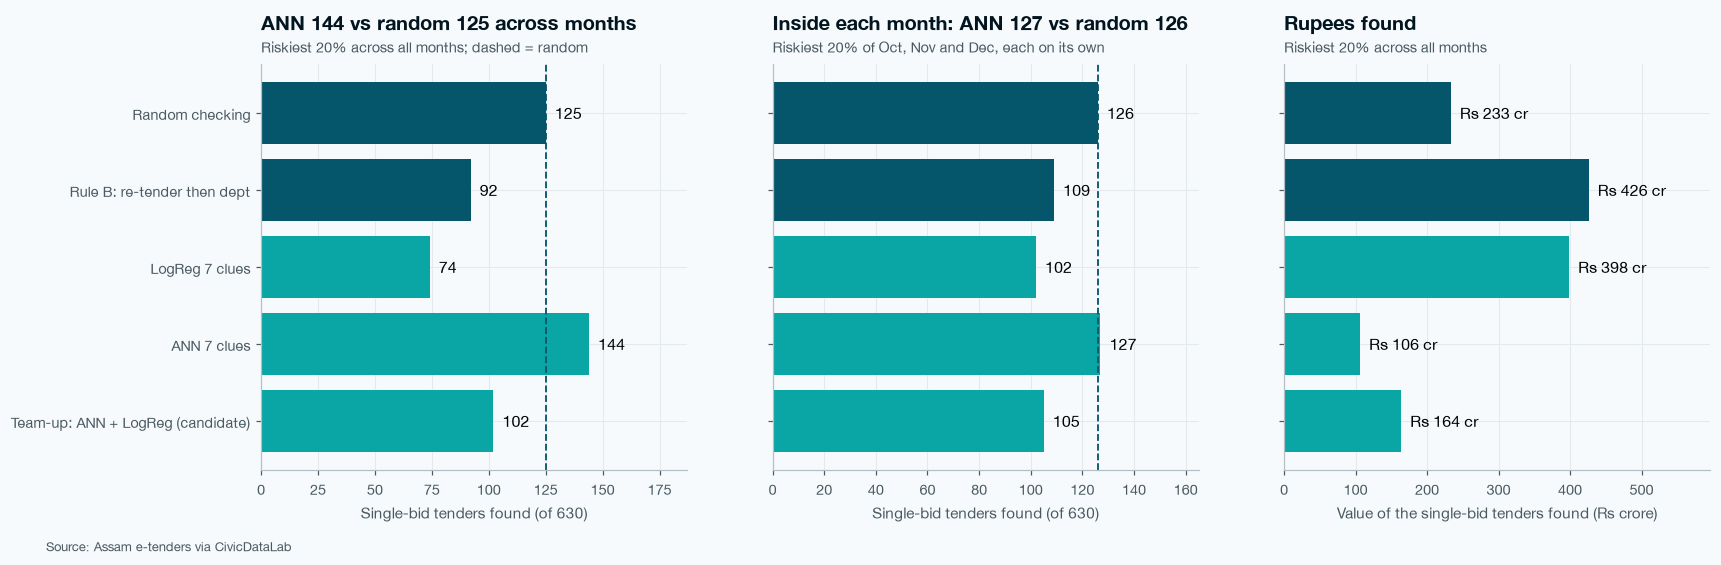

In [61]:
show = auditor  # every method
colors = np.where(show["method"].isin(benchmarks), ts.THIRD, ts.MULTI)  # benchmarks deep teal, models teal
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)  # three charts side by side
random_caught = show.loc[0, "caught (all months)"]  # random, for the dashed line

# left: caught across all months
b1 = axes[0].barh(show["method"], show["caught (all months)"], color=colors)  # one bar per method
axes[0].bar_label(b1, padding=6)  # numbers on bars
axes[0].axvline(random_caught, color=ts.THIRD, linestyle="--", linewidth=1.2)  # random
axes[0].set_xlim(0, show["caught (all months)"].max() * 1.3)  # room for labels
axes[0].invert_yaxis()  # first method on top
axes[0].set_xlabel("Single-bid tenders found (of " + str(all_single) + ")")  # x axis label
ts.title(axes[0], "ANN 144 vs random 125 across months", subtitle="Riskiest 20% across all months; dashed = random")  # left title

# middle: caught inside each month
b2 = axes[1].barh(show["method"], show["caught (inside each month)"], color=colors)  # one bar per method
axes[1].bar_label(b2, padding=6)  # numbers on bars
axes[1].axvline(show.loc[0, "caught (inside each month)"], color=ts.THIRD, linestyle="--", linewidth=1.2)  # random
axes[1].set_xlim(0, show["caught (inside each month)"].max() * 1.3)  # room for labels
axes[1].set_xlabel("Single-bid tenders found (of " + str(all_single) + ")")  # x axis label
ts.title(axes[1], "Inside each month: ANN 127 vs random 126", subtitle="Riskiest 20% of Oct, Nov and Dec, each on its own")  # middle title

# right: rupee value caught
b3 = axes[2].barh(show["method"], show["Rs crore caught"], color=colors)  # one bar per method
axes[2].bar_label(b3, fmt="Rs %.0f cr", padding=6)  # numbers on bars
axes[2].set_xlim(0, show["Rs crore caught"].max() * 1.4)  # room for labels
axes[2].set_xlabel("Value of the single-bid tenders found (Rs crore)")  # x axis label
ts.title(axes[2], "Rupees found", subtitle="Riskiest 20% across all months")  # right title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9g_auditor_view.png")  # save the chart

Precision at the very top of the list: out of the 50, 100 and 200 riskiest tenders, how many really got one bid? This is what an auditor with very little time would see.

In [62]:
prec_cols = ["method", "precision top 50", "precision top 100", "precision top 200"]  # the columns I want
race_table[prec_cols]  # show them for every method

,method,precision top 50,precision top 100,precision top 200
0,Random checking,38.000,32.000,30.500
1,Rule B: re-tender then dept,60.000,52.000,39.500
2,LogReg 7 clues,42.000,33.000,27.500
3,ANN 7 clues,38.000,33.000,33.000
4,Random (average of 500 draws),27.368,27.468,27.605
5,Team-up: ANN + LogReg (candidate),34.000,26.000,22.000


### Insight · Auditor view (Step 15)

- The auditor checks 454 tenders (20% of validation). There are 630 single-bid tenders in total.
- Across all months the ANN found 144, random 125, Rule B 92 and LogReg 74. At first this looks like a clear ANN win (19 more than random).
- But when I take the riskiest 20% inside each month (the way the app will work), the ANN found 127 and random 126. The win almost disappears.
- This means most of the 144 came from the ANN pushing whole months up (it ranked more October and November tenders on top, and those months had more single bids). It was not better at picking tenders inside a month.
- In money the ANN did badly: the single-bid tenders it found are worth only Rs 106 crore, compared with Rs 233 crore for random, Rs 398 crore for LogReg and Rs 426 crore for Rule B (all single-bid validation tenders are worth Rs 1,316 crore). So the ANN mostly found smaller tenders.
- At the very top of the list Rule B is still the strongest: 60% of its 50 riskiest tenders really got one bid. The ANN had 38%, the same as random.

### Step 16 · Risk bands for the ANN

In S7 the bands worked in the right order on test (High 28.6%, Medium 24.9%, Low 21.3%). Here I check whether the ANN's bands also work in the right order on validation: High = riskiest 20%, Medium = next 30%, Low = bottom 50%. I rank inside each month, the way the app will do it, and I put LogReg next to it.

In [63]:
def month_bands(col):  # helper 14: High / Medium / Low band of every tender, ranked inside its month
    share = val.groupby("month_name")[col].rank(ascending=False, pct=True, method="first")  # 0 = riskiest, 1 = safest, inside the month
    return np.where(share <= 0.2, "High", np.where(share <= 0.5, "Medium", "Low"))  # top 20% High, next 30% Medium, rest Low

In [64]:
val["band_ann"] = month_bands("risk_ann")  # ANN bands
val["band_lr"] = month_bands("risk_lr")  # LogReg bands
band_order = ["High", "Medium", "Low"]  # band order
band_table = pd.DataFrame()  # empty table
band_table["tenders"] = val["band_ann"].value_counts().reindex(band_order)  # tenders per band
band_table["ANN single-bid %"] = (val.groupby("band_ann")["single_bid"].mean() * 100).reindex(band_order).round(1)  # ANN bands
band_table["LogReg single-bid %"] = (val.groupby("band_lr")["single_bid"].mean() * 100).reindex(band_order).round(1)  # LogReg bands
band_table.to_csv(rep_dir + "/s9_risk_bands.csv")  # save it
band_table  # show it

,tenders,ANN single-bid %,LogReg single-bid %
band_ann,,,
High,453,28.0,22.5
Medium,681,27.0,27.8
Low,1136,28.1,29.8


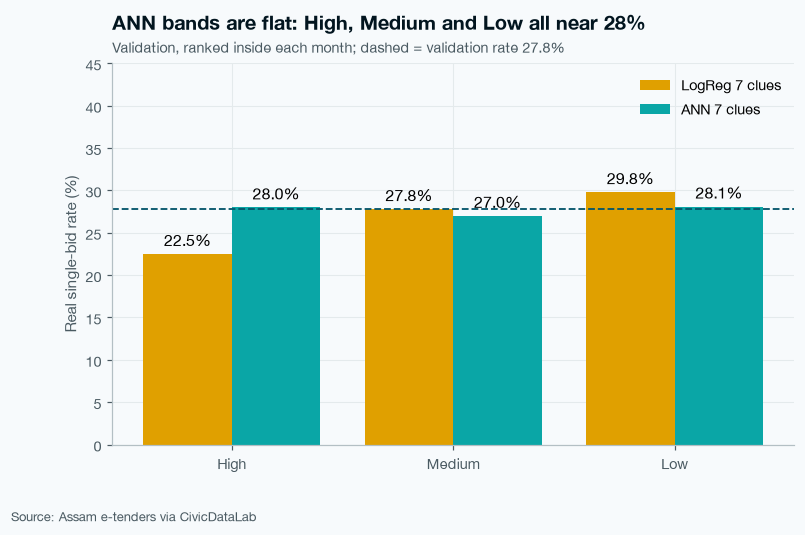

In [65]:
fig, ax = plt.subplots(figsize=(8, 4.5))  # one chart
pos = np.arange(len(band_order))  # one position per band
b1 = ax.bar(pos - 0.2, band_table["LogReg single-bid %"], width=0.4, color=ts.SINGLE, label="LogReg 7 clues")  # LogReg bands
b2 = ax.bar(pos + 0.2, band_table["ANN single-bid %"], width=0.4, color=ts.MULTI, label="ANN 7 clues")  # ANN bands
ax.bar_label(b1, fmt="%.1f%%", padding=3)  # labels
ax.bar_label(b2, fmt="%.1f%%", padding=3)  # labels
ax.axhline(val_rate, color=ts.THIRD, linestyle="--", linewidth=1.2)  # validation single-bid rate
ax.set_xticks(pos, band_order)  # band names
ax.set_ylim(0, 45)  # headroom
ax.set_ylabel("Real single-bid rate (%)")  # y axis label
ax.legend(loc="upper right")  # legend
subtitle = "Validation, ranked inside each month; dashed = validation rate " + str(round(val_rate, 1)) + "%"  # what is measured
ts.title(ax, "ANN bands are flat: High, Medium and Low all near 28%", subtitle=subtitle)  # the finding
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9h_risk_bands.png")  # save the chart

### Insight · Risk bands (Step 16)

- I ranked inside each month and made High (top 20%), Medium (next 30%) and Low (bottom 50%) bands.
- ANN bands: High 28.0%, Medium 27.0%, Low 28.1%. They are flat, so the ANN bands do not tell the auditor where to look first.
- LogReg bands on validation were upside down: High 22.5%, Medium 27.8%, Low 29.8%. This fits S5, where LogReg was below random on validation.
- For comparison, on test in S7 the LogReg bands worked in the right order (28.6 / 24.9 / 21.3). So neither model has bands that work in every period.

### Step 17 · Do the ANN and LogReg pick the same tenders?

If the ANN puts almost the same tenders in its riskiest 20% as LogReg, then it is mostly LogReg in a fancier coat, and it adds little. If the lists are very different, the ANN is seeing something else (good or bad). Here I count how many tenders the two riskiest-20% lists share, and how many single-bid tenders each list finds that the other one misses.

In [66]:
top_ann = set(top20("risk_ann")["tender_id"])  # ANN riskiest 20%
top_lr = set(top20("risk_lr")["tender_id"])  # LogReg riskiest 20%
both = top_ann & top_lr  # tenders in both lists
only_ann = top_ann - top_lr  # only in the ANN list
only_lr = top_lr - top_ann  # only in the LogReg list
single_ids = set(val.loc[val["single_bid"] == 1, "tender_id"])  # all single-bid tenders

In [67]:
overlap = {}  # one small table, key by key
overlap["in both lists"] = [len(both), len(both & single_ids)]  # shared tenders and how many are single-bid
overlap["only ANN"] = [len(only_ann), len(only_ann & single_ids)]  # only ANN
overlap["only LogReg"] = [len(only_lr), len(only_lr & single_ids)]  # only LogReg
overlap_table = pd.DataFrame(overlap, index=["tenders", "single-bid"]).T  # rows = groups
overlap_table["single-bid %"] = (overlap_table["single-bid"] / overlap_table["tenders"] * 100).round(1)  # rate in each group
overlap_table.to_csv(rep_dir + "/s9_overlap.csv")  # save it
shared_share = len(both) / n_check * 100  # share of the list that is shared
print("Shared:", len(both), "of", n_check, "=", round(shared_share, 1), "%")  # how similar the two lists are
overlap_table  # show it

Shared: 84 of 454 = 18.5 %


,tenders,single-bid,single-bid %
in both lists,84,21,25.0
only ANN,370,123,33.2
only LogReg,370,53,14.3


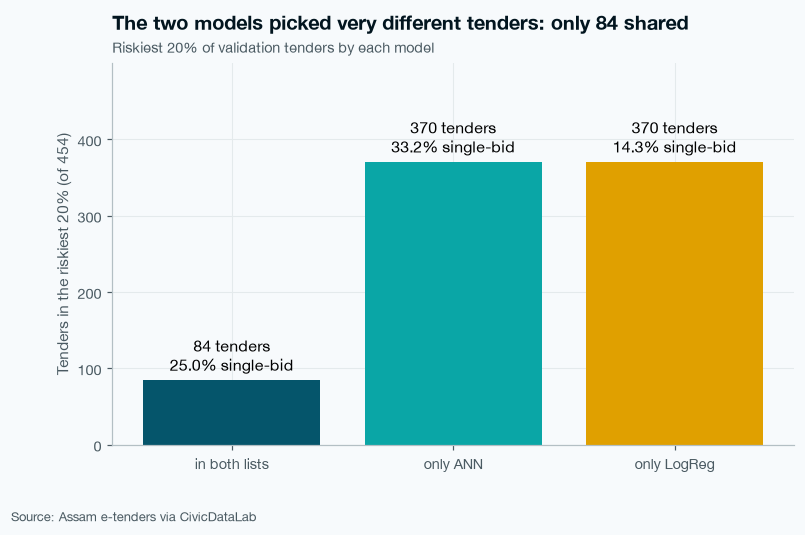

In [68]:
fig, ax = plt.subplots(figsize=(8, 4.5))  # one chart
groups = list(overlap_table.index)  # the three groups
bars = ax.bar(groups, overlap_table["tenders"], color=[ts.BLUES[4], ts.MULTI, ts.SINGLE])  # tenders in each group
labels = []  # label for each bar
for g in groups:  # one label per group
    labels.append(str(overlap_table.loc[g, "tenders"]) + " tenders\n" + str(overlap_table.loc[g, "single-bid %"]) + "% single-bid")  # two-line label
ax.bar_label(bars, labels=labels, padding=4)  # write the labels
ax.set_ylim(0, overlap_table["tenders"].max() * 1.35)  # headroom
ax.set_ylabel("Tenders in the riskiest 20% (of " + str(n_check) + ")")  # y axis label
subtitle = "Riskiest 20% of validation tenders by each model"  # what is measured
ts.title(ax, "The two models picked very different tenders: only 84 shared", subtitle=subtitle)  # the finding
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9i_overlap.png")  # save the chart

### Insight · Do the two models pick the same tenders? (Step 17)

- Only 84 of the 454 riskiest tenders (18.5%) were in both lists. So the ANN is not LogReg in a fancier coat. It looks at the tenders in a very different way.
- The 370 tenders only the ANN picked had 33.2% single-bid. The 370 only LogReg picked had just 14.3%. The 84 shared ones had 25.0%.
- So on validation, the ANN's own picks were better than LogReg's own picks. But they were still not better than random checking overall, as the bootstrap showed.

### Step 18 · Which clues does the ANN lean on? (permutation importance)

An ANN does not give simple weights like LogReg. So I use permutation importance: I shuffle one clue at a time across the validation tenders (so that clue becomes nonsense) and see how much the PR-AUC drops. A big drop means the ANN leans on that clue a lot. No drop means it hardly uses it. I shuffle each clue 10 times and take the average, so one lucky shuffle does not decide.

I use this instead of SHAP for the network, because SHAP and Keras 3 often do not work well together. If the ANN wins the app slot, I can try SHAP later.

In [69]:
def shuffle_drop(net, x, y, col_index, rng_p):  # helper 15: average PR-AUC drop when one clue is shuffled 10 times
    start_pr = average_precision_score(y, ann_risk(net, x))  # PR-AUC with nothing shuffled
    drops = []  # one drop per shuffle
    for i in range(10):  # 10 shuffles
        x_shuf = x.copy()  # copy so the real clues stay safe
        x_shuf[:, col_index] = rng_p.permutation(x_shuf[:, col_index])  # shuffle this one clue
        drops.append(start_pr - average_precision_score(y, ann_risk(net, x_shuf)))  # how much PR-AUC fell
    return np.mean(drops)  # average drop

In [70]:
rng_perm = np.random.default_rng(42)  # fixed seed for the shuffles
perm_rows = []  # one row per clue
for i, clue in enumerate(base):  # every clue
    row = {}  # empty row
    row["clue"] = nice[clue]  # easy name
    row["PR-AUC drop when shuffled"] = round(shuffle_drop(ann, x_val, y_val, i, rng_perm), 4)  # importance
    row["LogReg weight"] = round(lr.coef_[0][i], 3)  # LogReg weight, to compare
    perm_rows.append(row)  # add the row
perm_table = pd.DataFrame(perm_rows).sort_values("PR-AUC drop when shuffled", ascending=False)  # biggest first
perm_table.to_csv(rep_dir + "/s9_permutation.csv", index=False)  # save it
perm_table  # show it

,clue,PR-AUC drop when shuffled,LogReg weight
1,Tender value (log),0.0412,-0.007
4,Months to financial year end,0.0089,0.120
2,Value not written,0.0087,-0.193
5,Lot posted the same day,0.0081,0.031
6,Re-tender within 60 days,0.0008,-0.002
3,Days to submit bids,-0.0294,0.114
0,Department's past single-bid rate,-0.0364,0.234


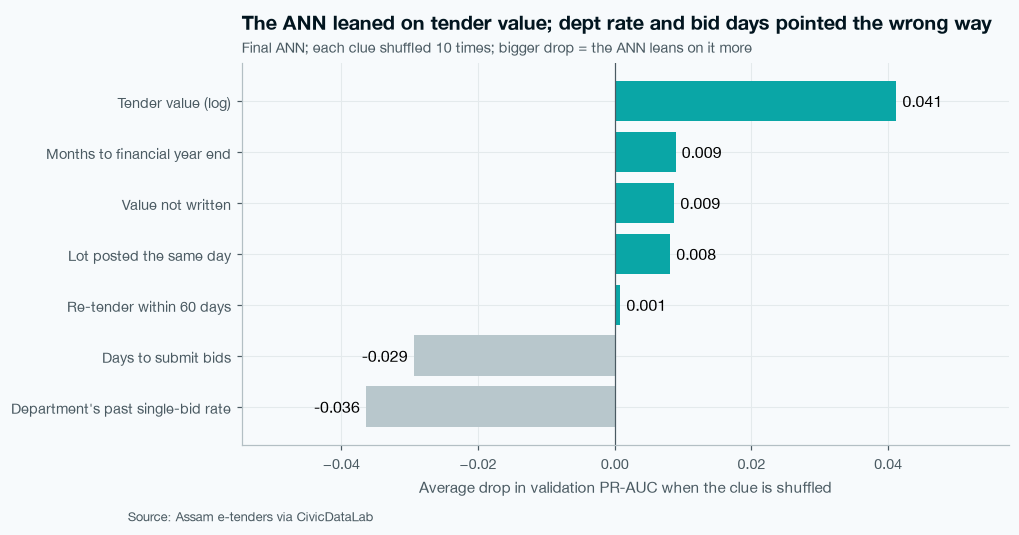

In [71]:
fig, ax = plt.subplots(figsize=(9, 4.5))  # one chart
show = perm_table.sort_values("PR-AUC drop when shuffled")  # smallest at the bottom of the list
bar_colors = np.where(show["PR-AUC drop when shuffled"] > 0, ts.MULTI, ts.NEUTRAL)  # teal = the ANN uses it
bars = ax.barh(show["clue"], show["PR-AUC drop when shuffled"], color=bar_colors)  # one bar per clue
ax.bar_label(bars, fmt="%.3f", padding=4)  # numbers on bars
ax.axvline(0, color=ts.INK2, linewidth=0.8)  # zero line
ax.set_xlim(min(show["PR-AUC drop when shuffled"].min() * 1.5, -0.005), show["PR-AUC drop when shuffled"].max() * 1.4)  # room for labels
ax.set_xlabel("Average drop in validation PR-AUC when the clue is shuffled")  # x axis label
subtitle = "Final ANN; each clue shuffled 10 times; bigger drop = the ANN leans on it more"  # what is measured
ts.title(ax, "The ANN leaned on tender value; dept rate and bid days pointed the wrong way", subtitle=subtitle)  # the finding
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9j_permutation.png")  # save the chart

### Insight · Which clues the ANN leans on (Step 18)

- When I shuffled tender value, the ANN's PR-AUC dropped the most (by 0.041). So the ANN leaned mostly on tender value. LogReg gave tender value almost no weight (-0.007), so this is one clear difference between the two models.
- Months to financial year end (0.009), value not written (0.009) and lot posted the same day (0.008) helped a little. Re-tender within 60 days hardly mattered (0.001).
- Shuffling the department's past single-bid rate (-0.036) and days to submit bids (-0.029) made the ANN better, not worse. This means these two clues pointed the wrong way on validation. They are exactly the clues that flipped after Sep 2022 (S5 drift and the S7 clue direction check).
- LogReg gave its biggest weight to department rate (+0.234). That is one reason why LogReg was upside down on validation.

### Step 19 · Extra try: ANN with all 34 clues

In S5, LogReg, Random Forest and XGBoost with all 34 clues were not better than with 7. An ANN can sometimes use many clues better, so I try it once. I follow the same recipe: scale on the learn part, pick the number of rounds with the stop signal part, then retrain on all training months for that many rounds. I keep the chosen layer sizes and dropout from Step 8.

In [72]:
scaler34 = StandardScaler()  # a scaler for the 34 clues
scaler34.fit(learn[all_clues])  # sizes from the learn part only
net34, hist34, best34 = train_with_stop(scaler34.transform(learn[all_clues]), y_learn, scaler34.transform(stop[all_clues]), y_stop, pick_sizes, pick_drop, 42)  # find the best number of rounds
print("34 clues - best round:", best34)  # rounds to use

34 clues - best round: 10


In [73]:
scaler34_tr = StandardScaler()  # a new scaler for the final 34-clue network
scaler34_tr.fit(train[all_clues])  # sizes from all training tenders
ann34 = train_full(scaler34_tr.transform(train[all_clues]), y_train, pick_sizes, pick_drop, best34, 42)  # retrain on all training months
val["risk_ann34"] = ann_risk(ann34, scaler34_tr.transform(val[all_clues]))  # validation scores
methods["risk_ann34"] = "ANN 34 clues"  # add to the methods list
race_table = pd.concat([race_table, pd.DataFrame([score_row("ANN 34 clues", y_val, val["risk_ann34"].values)])], ignore_index=True)  # add its row
race_table[["method", "PR-AUC", "ROC-AUC", "capture top 20%"]]  # show the main scores

,method,PR-AUC,ROC-AUC,capture top 20%
0,Random checking,0.288,0.514,19.800
1,Rule B: re-tender then dept,0.268,0.431,14.600
2,LogReg 7 clues,0.252,0.426,11.700
3,ANN 7 clues,0.286,0.475,22.900
4,Random (average of 500 draws),0.280,0.500,19.983
5,Team-up: ANN + LogReg (candidate),0.253,0.443,16.200
6,ANN 34 clues,0.256,0.447,18.100


### Step 20 · Optional: ANN on the MiniLM text embeddings

In S6 the embeddings (384 meaning numbers that MiniLM made from each tender's title and description) were my best fair text method on validation (PR-AUC 0.300 with LogReg, but not proven by the bootstrap). Neural networks are a natural fit for this kind of input, so here I try two versions: embeddings alone, and embeddings plus my 7 clues.

The meaning numbers for train and validation were saved in S6 in the same row order as the train and validation tenders in my clue table, so I can glue them back on. Same recipe as before: learn part, stop signal part, then retrain on all training months.

In [74]:
emb_tv = np.load("../data/processed/s6_embeddings_train_val.npy")  # meaning numbers for train + validation (S6)
tv = lab[lab["split"] != "test"]  # train + validation tenders in the same order as the file
emb_cols = []  # names e0, e1, ... e383
for i in range(emb_tv.shape[1]):  # one name per meaning number
    emb_cols.append("e" + str(i))  # add the name
emb_table = pd.DataFrame(emb_tv, index=tv.index, columns=emb_cols)  # meaning numbers with the same row labels
print("Embeddings:", emb_table.shape)  # should be 5,023 x 384

Embeddings: (5023, 384)


In [75]:
learn = learn.join(emb_table)  # add meaning numbers to the learn part
stop = stop.join(emb_table)  # add them to the stop signal part
train = train.join(emb_table)  # add them to all training tenders
val = val.join(emb_table)  # add them to validation
emb_plus = emb_cols + base  # embeddings plus the 7 clues
print("Missing meaning numbers in validation:", int(val[emb_cols].isna().sum().sum()))  # should be 0

Missing meaning numbers in validation: 0


The text network gets 384 inputs, so it has many more numbers to learn than my small 7-clue network. With only about 1,800 learning tenders it could memorise very fast. So I give it one layer of 32 helpers and a stronger dropout (30%). I set this before looking at any validation result, and I do not change it after.

In [76]:
def text_ann(cols):  # helper 16: the full recipe for a text network on the given columns
    sc = StandardScaler()  # scaler for these columns
    sc.fit(learn[cols])  # sizes from the learn part only
    net_s, hist_s, best_s = train_with_stop(sc.transform(learn[cols]), y_learn, sc.transform(stop[cols]), y_stop, [32], 0.3, 42)  # find the best number of rounds
    sc_tr = StandardScaler()  # new scaler for the final network
    sc_tr.fit(train[cols])  # sizes from all training tenders
    net_f = train_full(sc_tr.transform(train[cols]), y_train, [32], 0.3, best_s, 42)  # retrain on all training months
    return ann_risk(net_f, sc_tr.transform(val[cols])), best_s  # validation scores and best round

In [77]:
val["risk_ann_emb"], best_emb = text_ann(emb_cols)  # embeddings alone
val["risk_ann_emb7"], best_emb7 = text_ann(emb_plus)  # embeddings + 7 clues
print("Best rounds - embeddings alone:", best_emb, "| embeddings + 7 clues:", best_emb7)  # rounds used

Best rounds - embeddings alone: 3 | embeddings + 7 clues: 3


In [78]:
methods["risk_ann_emb"] = "ANN embeddings (text)"  # add to the methods list
methods["risk_ann_emb7"] = "ANN embeddings + 7 clues"  # add to the methods list
race_table = pd.concat([race_table, pd.DataFrame([score_row("ANN embeddings (text)", y_val, val["risk_ann_emb"].values)])], ignore_index=True)  # add row
race_table = pd.concat([race_table, pd.DataFrame([score_row("ANN embeddings + 7 clues", y_val, val["risk_ann_emb7"].values)])], ignore_index=True)  # add row

For comparison I add the S6 LogReg on embeddings (0.300) from my saved S6 results, without re-running it. Then I run the bootstrap for the two text networks against random checking.

In [79]:
s6 = pd.read_csv(rep_dir + "/s6_nlp_results.csv")  # S6 results table
s6_emb = s6[s6["model"] == "Embeddings alone"].iloc[0]  # the S6 LogReg on embeddings row
s6_row = {}  # one row for the table
s6_row["method"] = "S6 LogReg embeddings (saved)"  # name
s6_row["PR-AUC"] = s6_emb["PR-AUC"]  # PR-AUC from S6
s6_row["ROC-AUC"] = s6_emb["ROC-AUC"]  # ROC-AUC from S6
s6_row["capture top 20%"] = s6_emb["capture top 20%"]  # capture from S6
race_table = pd.concat([race_table, pd.DataFrame([s6_row])], ignore_index=True)  # add its row

In [80]:
for p in [["risk_ann_emb", "risk_random", "ANN embeddings vs Random"], ["risk_ann_emb7", "risk_random", "ANN embeddings + 7 clues vs Random"]]:  # two more pairs
    boot_rows.append(boot_row(p[2], bootstrap(p[0], p[1])))  # add the row
boot_table = pd.DataFrame(boot_rows)  # updated bootstrap table
boot_table.to_csv(rep_dir + "/s9_bootstrap.csv", index=False)  # save it again
boot_table  # show it

,comparison,A wins (% of draws),gap low (2.5%),gap high (97.5%)
0,ANN vs Random,43.0,-0.031,0.027
1,ANN vs LogReg,99.8,0.006,0.061
2,ANN vs Rule B,88.0,-0.013,0.046
3,Team-up vs Random,0.0,-0.061,-0.010
4,ANN embeddings vs Random,15.8,-0.042,0.012
5,ANN embeddings + 7 clues vs Random,2.8,-0.052,0.000


Now the full race table on validation, with every method in this section, and one chart that puts them all side by side.

In [81]:
race_table.to_csv(rep_dir + "/s9_val_results.csv", index=False)  # save the full race table
race_table[["method", "PR-AUC", "ROC-AUC", "capture top 20%", "lift top 20%"]]  # show the main scores

,method,PR-AUC,ROC-AUC,capture top 20%,lift top 20%
0,Random checking,0.288,0.514,19.800,0.990
1,Rule B: re-tender then dept,0.268,0.431,14.600,0.730
2,LogReg 7 clues,0.252,0.426,11.700,0.590
3,ANN 7 clues,0.286,0.475,22.900,1.140
4,Random (average of 500 draws),0.280,0.500,19.983,0.999
5,Team-up: ANN + LogReg (candidate),0.253,0.443,16.200,0.810
6,ANN 34 clues,0.256,0.447,18.100,0.900
7,ANN embeddings (text),0.274,0.478,23.200,1.160
8,ANN embeddings + 7 clues,0.264,0.465,22.200,1.110
9,S6 LogReg embeddings (saved),0.300,0.507,22.700,NaN


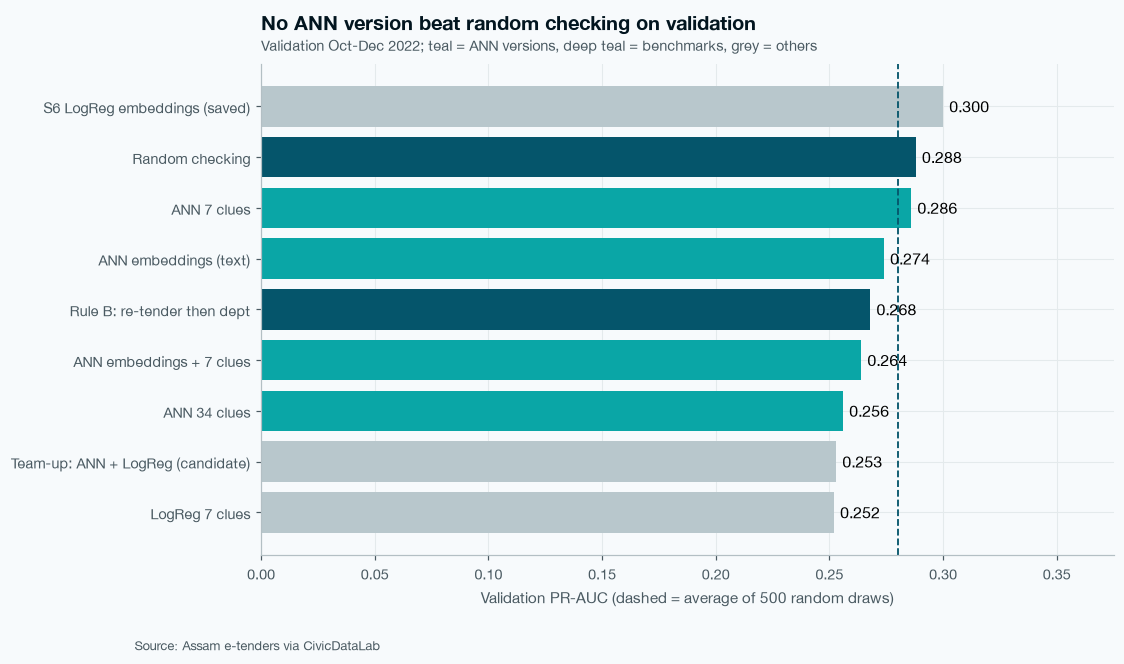

In [82]:
show = race_table[race_table["method"] != "Random (average of 500 draws)"].sort_values("PR-AUC", ascending=True)  # every method, best at the top
bar_colors = []  # one colour per bar
for name in show["method"]:  # pick the colour by role
    if name in benchmarks:  # benchmarks
        bar_colors.append(ts.THIRD)  # deep teal
    elif name.startswith("ANN"):  # my new networks
        bar_colors.append(ts.MULTI)  # teal
    else:  # LogReg, the team-up and the S6 number
        bar_colors.append(ts.NEUTRAL)  # grey
fig, ax = plt.subplots(figsize=(10, 5.8))  # one chart
bars = ax.barh(show["method"], show["PR-AUC"], color=bar_colors)  # one bar per method
ax.bar_label(bars, fmt="%.3f", padding=4)  # numbers on bars
ax.axvline(random_pr, color=ts.THIRD, linestyle="--", linewidth=1.2)  # random average
ax.set_xlim(0, show["PR-AUC"].max() * 1.25)  # room for labels
ax.set_xlabel("Validation PR-AUC (dashed = average of 500 random draws)")  # x axis label
subtitle = "Validation Oct-Dec 2022; teal = ANN versions, deep teal = benchmarks, grey = others"  # what is measured
ts.title(ax, "No ANN version beat random checking on validation", subtitle=subtitle)  # the finding
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9k_all_methods.png")  # save the chart

### Insight · 34 clues and the text embeddings (Steps 19 and 20)

- ANN with all 34 clues: PR-AUC 0.256 and 18.1% found. Worse than the 7-clue ANN, the same lesson as S5: more clues did not help.
- ANN on the MiniLM embeddings alone: 0.274 and 23.2% found. ANN on embeddings + 7 clues: 0.264 and 22.2%.
- Both text networks stopped at round 3, so they also learned very little before the stop signal said stop.
- Bootstrap against random: embeddings ANN won only 15.8% of the draws and embeddings + 7 clues only 2.8%. So neither is better than random checking.
- The simple S6 LogReg on embeddings (0.300) is still my best fair text result. The network did not improve on it.
- Full validation ranking: S6 LogReg embeddings 0.300, random 0.288, ANN 7 clues 0.286, ANN embeddings 0.274, Rule B 0.268, ANN embeddings + 7 clues 0.264, ANN 34 clues 0.256, team-up 0.253, LogReg 0.252.

## Part D · Test months, only as a description

### Step 21 · The ANN learned once, scored on Jan-May 2023

The test answers were opened once in S7 with a locked plan. Anything I do on test now is NOT a new fair test, because I already know the answers. I only do it to describe how the ANN would have done, next to the S7 numbers.

To keep it close to S7, the ANN learns once from all train and validation tenders whose bids were opened before 1 Jan 2023 (the same rule S7 used for the learned-once models). It uses the layers, dropout and number of rounds I chose in Part B. Nothing is tuned on test. I also learn LogReg the same way as a check: S7 got PR-AUC 0.258 for learned-once LogReg.

In [83]:
tv_all = lab[lab["split"] != "test"].copy()  # train + validation tenders
learn_once = tv_all[tv_all["bid_opening_date"] < "2023-01-01"]  # only those opened before 1 Jan 2023
y_te = test["single_bid"].values  # test answers (already opened in S7)
test_rate = y_te.mean() * 100  # test single-bid rate
print("Learns from:", len(learn_once), "tenders | test:", len(test), "tenders,", round(test_rate, 1), "% single-bid")  # sizes

Learns from: 4575 tenders | test: 1767 tenders, 23.8 % single-bid


In [84]:
scaler_once = StandardScaler()  # scaler for the learned-once models
scaler_once.fit(learn_once[base])  # sizes from the learning tenders
x_once = scaler_once.transform(learn_once[base])  # scaled learning clues
x_te = scaler_once.transform(test[base])  # scaled test clues
ann_once = train_full(x_once, learn_once["single_bid"].values, pick_sizes, pick_drop, pick_round, 42)  # the ANN, learned once
test["risk_ann"] = ann_risk(ann_once, x_te)  # ANN test scores
lr_once = LogisticRegression(class_weight="balanced", max_iter=3000)  # LogReg, learned once (check)
lr_once.fit(x_once, learn_once["single_bid"])  # learn from the same tenders
test["risk_lr_once"] = lr_once.predict_proba(x_te)[:, 1]  # LogReg test scores

In [85]:
s7_pred = pd.read_csv(rep_dir + "/s7_test_predictions.csv")  # S7 test scores (random, Rule B, monthly main model)
test = test.merge(s7_pred[["tender_id", "risk_random", "risk_ruleb", "risk_main"]], on="tender_id", how="left")  # add them by tender id
y_te = test["single_bid"].values  # answers again, in the merged row order

In [86]:
def caught_top20(y, risk):  # helper 17: number of single-bid tenders in the riskiest 20%
    t = pd.DataFrame({"real": np.asarray(y), "risk": np.asarray(risk)})  # answers and scores side by side
    t = t.sort_values("risk", ascending=False, kind="stable")  # riskiest first
    return int(t.head(int(len(t) * 0.2))["real"].sum())  # how many single-bid tenders are in the top 20%

In [87]:
test_methods = {}  # risk column -> name
test_methods["risk_random"] = "Random checking (S7)"  # benchmark 1
test_methods["risk_ruleb"] = "Rule B (S7)"  # benchmark 2
test_methods["risk_main"] = "LogReg monthly, main model (S7)"  # the S7 main model
test_methods["risk_lr_once"] = "LogReg learned once"  # check against S7's 0.258
test_methods["risk_ann"] = "ANN learned once"  # the new network
test_rows = []  # one row per method
for col in test_methods:  # score every method on test
    row = score_row(test_methods[col], y_te, test[col].values)  # all scores
    row["caught in top 20%"] = caught_top20(y_te, test[col].values)  # single-bid tenders found
    test_rows.append(row)  # add the row
test_table = pd.DataFrame(test_rows)  # the test description table
test_table.to_csv(rep_dir + "/s9_test_description.csv", index=False)  # save it
test_table[["method", "PR-AUC", "ROC-AUC", "capture top 20%", "caught in top 20%"]]  # show the main scores

,method,PR-AUC,ROC-AUC,capture top 20%,caught in top 20%
0,Random checking (S7),0.232,0.499,18.8,79
1,Rule B (S7),0.279,0.507,25.7,108
2,"LogReg monthly, main model (S7)",0.256,0.552,24.0,101
3,LogReg learned once,0.258,0.552,24.2,102
4,ANN learned once,0.232,0.483,18.5,78


PR-AUC depends on how common single-bid tenders are, and test has fewer of them than validation. So, like S7, I divide PR-AUC by the single-bid rate to get "times better than random" (1.0 = same as random), and compare validation with test.

In [88]:
vt = {}  # one row per model: times better than random in validation and test
vt["LogReg 7 clues"] = [lr_pr / (val_rate / 100), test_table.loc[test_table["method"] == "LogReg learned once", "PR-AUC"].iloc[0] / (test_rate / 100)]  # LogReg
vt["ANN 7 clues"] = [ann_pr / (val_rate / 100), test_table.loc[test_table["method"] == "ANN learned once", "PR-AUC"].iloc[0] / (test_rate / 100)]  # ANN
vt["Rule B"] = [race_table.loc[race_table["method"] == "Rule B: re-tender then dept", "PR-AUC"].iloc[0] / (val_rate / 100), test_table.loc[test_table["method"] == "Rule B (S7)", "PR-AUC"].iloc[0] / (test_rate / 100)]  # Rule B
vt_table = pd.DataFrame(vt, index=["validation x random", "test x random"]).T.round(2)  # rows = models
vt_table  # show it

,validation x random,test x random
LogReg 7 clues,0.91,1.08
ANN 7 clues,1.03,0.97
Rule B,0.97,1.17


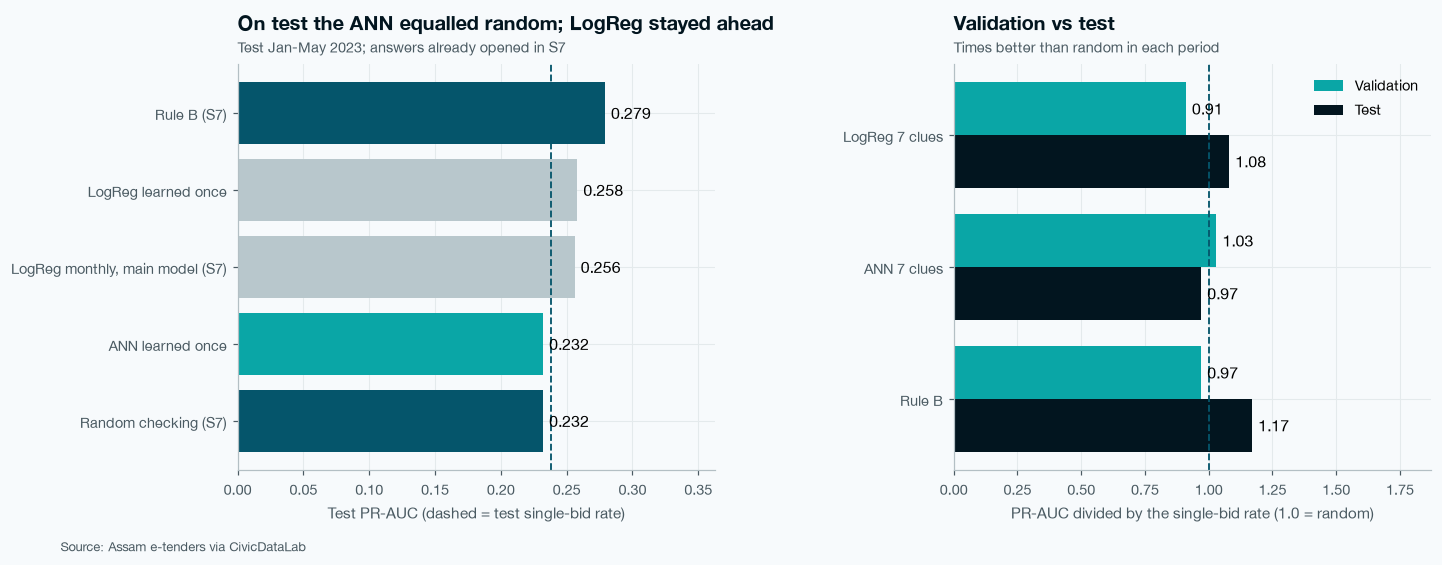

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))  # two charts side by side

# left: test PR-AUC of every method, random as the dashed line
show = test_table.sort_values("PR-AUC")  # lowest at the bottom
bar_colors = []  # colour by role
for name in show["method"]:  # one colour per bar
    if name.startswith("ANN"):  # the new network
        bar_colors.append(ts.MULTI)  # teal
    elif name.startswith("Random") or name.startswith("Rule"):  # benchmarks
        bar_colors.append(ts.THIRD)  # deep teal
    else:  # the LogReg versions
        bar_colors.append(ts.NEUTRAL)  # grey
bars = axes[0].barh(show["method"], show["PR-AUC"], color=bar_colors)  # one bar per method
axes[0].bar_label(bars, fmt="%.3f", padding=4)  # numbers on bars
axes[0].axvline(test_rate / 100, color=ts.THIRD, linestyle="--", linewidth=1.2)  # what random gets on average (the single-bid rate)
axes[0].set_xlim(0, show["PR-AUC"].max() * 1.3)  # room for labels
axes[0].set_xlabel("Test PR-AUC (dashed = test single-bid rate)")  # x axis label
ts.title(axes[0], "On test the ANN equalled random; LogReg stayed ahead", subtitle="Test Jan-May 2023; answers already opened in S7")  # left title

# right: times better than random, validation vs test
pos = np.arange(len(vt_table))  # one position per model
b1 = axes[1].barh(pos - 0.2, vt_table["validation x random"], height=0.4, color=ts.BLUES[3], label="Validation")  # validation
b2 = axes[1].barh(pos + 0.2, vt_table["test x random"], height=0.4, color=ts.BLUES[5], label="Test")  # test
axes[1].bar_label(b1, fmt="%.2f", padding=4)  # labels
axes[1].bar_label(b2, fmt="%.2f", padding=4)  # labels
axes[1].axvline(1.0, color=ts.THIRD, linestyle="--", linewidth=1.2)  # 1.0 = same as random
axes[1].set_yticks(pos, vt_table.index)  # model names
axes[1].invert_yaxis()  # first model on top
axes[1].set_xlim(0, vt_table.max().max() * 1.6)  # room for labels and the legend
axes[1].set_xlabel("PR-AUC divided by the single-bid rate (1.0 = random)")  # x axis label
axes[1].legend(loc="upper right")  # legend
ts.title(axes[1], "Validation vs test", subtitle="Times better than random in each period")  # right title
fig.subplots_adjust(wspace=0.5)  # space for the long names
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9l_test_description.png")  # save the chart

### Insight · Test months, only as a description (Step 21)

- These numbers are not a new fair test, because the test answers were opened in S7.
- The ANN learned once from 4,575 tenders (bids opened before 1 Jan 2023), using the size and rounds chosen in Part B. Nothing was tuned on test.
- On test (1,767 tenders, 23.8% single-bid) the ANN got PR-AUC 0.232 and found 78 single-bid tenders in its riskiest 20%. Random checking got 0.232 and 79. So the ANN was exactly the same as random.
- LogReg learned once got 0.258 and found 102. This matches S7 (0.258), so my check is correct. The S7 main model (monthly) had 0.256 and 101, and Rule B 0.279 and 108.
- Times better than random: the ANN went from 1.03 on validation to 0.97 on test. LogReg went from 0.91 to 1.08, and Rule B from 0.97 to 1.17.
- So the ANN looked a bit better than LogReg on validation, but LogReg was better on test. A model that wobbles like this is not one I can trust in the app.

## Part E · A short autoencoder (a second "odd one out" detector)

### Step 22 · Build and train the autoencoder

An autoencoder is a network that learns to copy its input. The trick is that it must squeeze the clues through a narrow middle (here only 3 numbers) and then draw them back out again. It is like learning to re-draw a normal tender from memory. It gets good at drawing normal tenders, so a tender it re-draws badly is odd.

I use the same 10 publish-day clues as my S8 Isolation Forest, so I can compare the two detectors fairly. It learns only from training tenders, with the same learn part and stop signal part as before.

| Part | Simple meaning |
|---|---|
| 10 inputs | the 10 Isolation Forest clues, scaled |
| 6 then 3 helpers | the squeeze: the network must keep only the main shape of the tender |
| 6 then 10 outputs | it draws the 10 clues back out |
| `loss="mse"` | mistake score = average squared gap between the real clue and the re-drawn clue |
| re-draw error | how badly one tender was re-drawn; a big error = odd tender |

In [90]:
iso_clues = list(pd.read_csv(model_dir + "/tenderlens_iforest_clues.csv").iloc[:, 0])  # the 10 clues of the S8 Isolation Forest
print("Autoencoder clues:", len(iso_clues))  # should be 10
print(iso_clues)  # their names

Autoencoder clues: 10
['dept_rate', 'log_value', 'value_missing', 'bid_window_days', 'months_to_fy_end', 'same_day_lot', 'retender_60d', 'emd_ratio', 'log_fee', 'work_period_days']


In [91]:
ae_scaler = StandardScaler()  # scaler for the autoencoder
ae_scaler.fit(learn[iso_clues])  # sizes from the learn part only
ae_learn = ae_scaler.transform(learn[iso_clues])  # scaled learn clues
ae_stop = ae_scaler.transform(stop[iso_clues])  # scaled stop signal clues

In [92]:
def build_ae(seed):  # helper 18: build and compile the autoencoder
    keras.utils.set_random_seed(seed)  # fix the random start
    ae_net = keras.Sequential()  # empty network
    ae_net.add(keras.Input(shape=(len(iso_clues),)))  # the door for the 10 clues
    ae_net.add(keras.layers.Dense(6, activation="relu"))  # squeeze step 1
    ae_net.add(keras.layers.Dense(3, activation="relu"))  # the narrow middle: 3 numbers
    ae_net.add(keras.layers.Dense(6, activation="relu"))  # draw back out, step 1
    ae_net.add(keras.layers.Dense(len(iso_clues)))  # draw back all 10 clues (no squeeze on the output)
    ae_net.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")  # teacher and mistake score
    return ae_net  # give back the network

In [93]:
def train_ae(seed):  # helper 19: train the autoencoder with early stopping on the stop signal part
    ae_net = build_ae(seed)  # a fresh autoencoder
    rule = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)  # early stopping rule
    hist = ae_net.fit(ae_learn, ae_learn, validation_data=(ae_stop, ae_stop), epochs=500, batch_size=32, callbacks=[rule], verbose=0)  # the answer is the input itself (up to 500 rounds, it learns slowly)
    return ae_net, hist  # give back the network and its history

In [94]:
ae, ae_hist = train_ae(42)  # the main autoencoder
ae_best = int(np.argmin(ae_hist.history["val_loss"])) + 1  # best round
print("Rounds run:", len(ae_hist.history["loss"]), "| best round:", ae_best)  # when it stopped

Rounds run: 286 | best round: 271


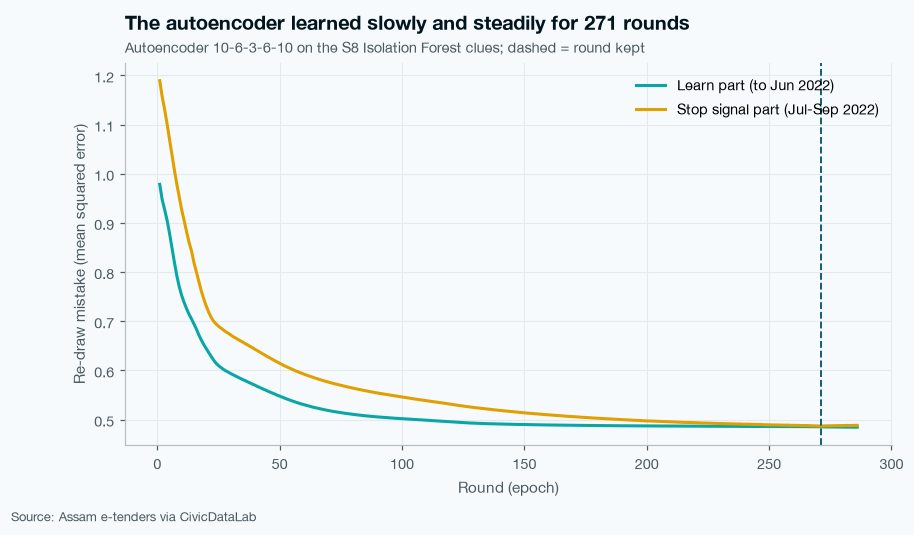

In [95]:
fig, ax = plt.subplots(figsize=(9, 4.5))  # one chart
ae_rounds = np.arange(1, len(ae_hist.history["loss"]) + 1)  # round numbers
ax.plot(ae_rounds, ae_hist.history["loss"], color=ts.MULTI, label="Learn part (to Jun 2022)")  # learn mistake
ax.plot(ae_rounds, ae_hist.history["val_loss"], color=ts.SINGLE, label="Stop signal part (Jul-Sep 2022)")  # stop signal mistake
ax.axvline(ae_best, color=ts.THIRD, linestyle="--", linewidth=1.2)  # round kept
ax.set_xlabel("Round (epoch)")  # x axis label
ax.set_ylabel("Re-draw mistake (mean squared error)")  # y axis label
ax.legend(loc="upper right")  # legend
subtitle = "Autoencoder 10-6-3-6-10 on the S8 Isolation Forest clues; dashed = round kept"  # what is measured
ts.title(ax, "The autoencoder learned slowly and steadily for 271 rounds", subtitle=subtitle)  # the finding
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9m_autoencoder_curve.png")  # save the chart

### Step 23 · Which tenders are odd, and does it agree with the Isolation Forest?

For every labelled tender I measure the re-draw error. Then, like S8, I set the cut-off at the top 5% of training errors, and every tender above it gets the "unusual" flag. Then I compare with the S8 Isolation Forest flags (saved in s8_anomaly_scores.csv).

In [96]:
def redraw_errors(ae_net, rows):  # helper 20: re-draw error of every tender in a table, plus the error per clue
    x = ae_scaler.transform(rows[iso_clues])  # scaled clues
    x_back = ae_net.predict(x, verbose=0)  # the re-drawn clues
    per_clue = (x - x_back) ** 2  # squared gap for every clue
    return per_clue.mean(axis=1), per_clue  # average gap per tender, and the gap per clue

In [97]:
ae_all = lab[["tender_id", "split", "single_bid"]].copy()  # one row per labelled tender
ae_all["ae_error"], ae_per_clue = redraw_errors(ae, lab)  # re-draw errors
ae_cut = np.percentile(ae_all.loc[ae_all["split"] == "train", "ae_error"], 95)  # top 5% of training errors
ae_all["ae_unusual"] = (ae_all["ae_error"] > ae_cut).astype(int)  # 1 = odd tender
print("Cut-off (top 5% of training errors):", round(ae_cut, 4))  # the line
ae_all.groupby("split")["ae_unusual"].agg(["sum", "mean"]).reindex(["train", "val", "test"])  # flagged per split

Cut-off (top 5% of training errors): 0.9998


,sum,mean
split,,
train,138,0.050127
val,131,0.057709
test,221,0.125071


In [98]:
iso = pd.read_csv(rep_dir + "/s8_anomaly_scores.csv")  # S8 Isolation Forest scores and flags
ae_all = ae_all.merge(iso[["tender_id", "anomaly_score", "unusual"]], on="tender_id", how="left")  # add them
ae_all = ae_all.rename(columns={"unusual": "iso_unusual"})  # clearer name
print("Missing Isolation Forest rows:", int(ae_all["iso_unusual"].isna().sum()))  # should be 0

Missing Isolation Forest rows: 0


In [99]:
agree_rows = []  # one row per split
for s in ["train", "val", "test"]:  # every split
    part = ae_all[ae_all["split"] == s]  # tenders of this split
    row = {}  # empty row
    row["split"] = s  # split name
    row["autoencoder flags"] = int(part["ae_unusual"].sum())  # odd by the autoencoder
    row["Isolation Forest flags"] = int(part["iso_unusual"].sum())  # odd by the Isolation Forest
    row["flagged by both"] = int(((part["ae_unusual"] == 1) & (part["iso_unusual"] == 1)).sum())  # odd by both
    row["share of AE flags also IF %"] = round(row["flagged by both"] / max(row["autoencoder flags"], 1) * 100, 1)  # agreement
    row["score rank match"] = round(part["ae_error"].corr(part["anomaly_score"], method="spearman"), 3)  # do the two scores rank tenders the same way? (1 = same)
    agree_rows.append(row)  # add the row
agree_table = pd.DataFrame(agree_rows)  # the agreement table
agree_table.to_csv(rep_dir + "/s9_autoencoder_overlap.csv", index=False)  # save it
agree_table  # show it

,split,autoencoder flags,Isolation Forest flags,flagged by both,share of AE flags also IF %,score rank match
0,train,138,138,75,54.3,0.842
1,val,131,35,19,14.5,0.469
2,test,221,74,37,16.7,0.821


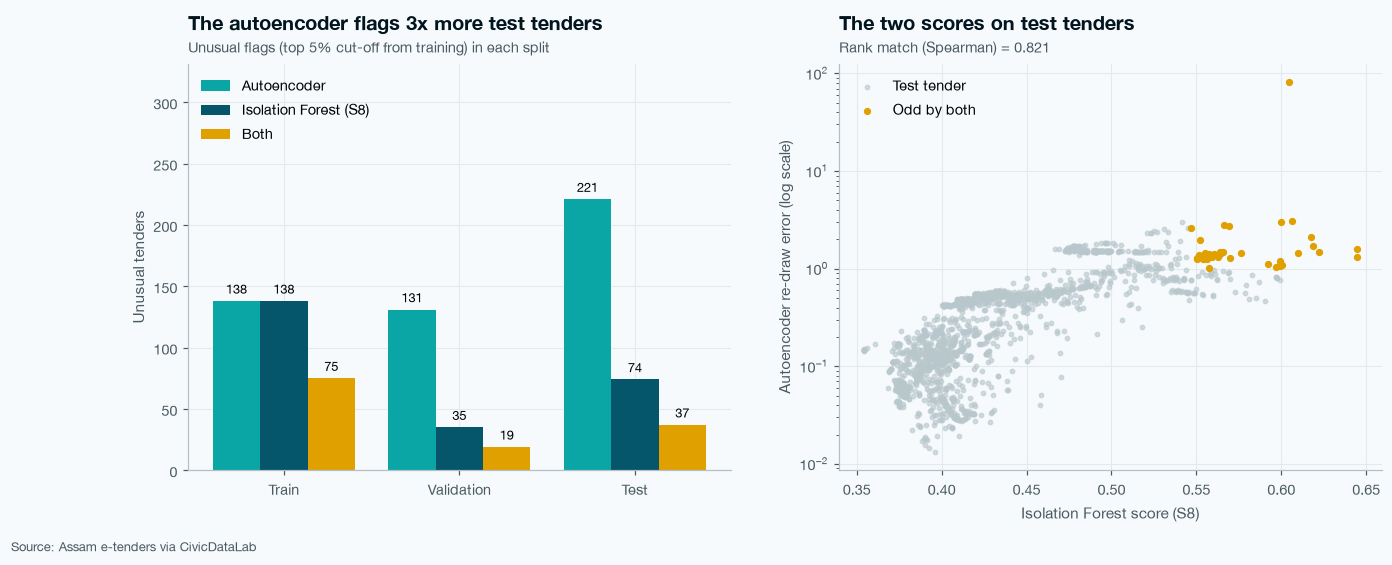

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))  # two charts side by side

# left: flags per split, autoencoder vs Isolation Forest vs both
pos = np.arange(len(agree_table))  # one position per split
b1 = axes[0].bar(pos - 0.27, agree_table["autoencoder flags"], width=0.27, color=ts.MULTI, label="Autoencoder")  # AE flags
b2 = axes[0].bar(pos, agree_table["Isolation Forest flags"], width=0.27, color=ts.THIRD, label="Isolation Forest (S8)")  # IF flags
b3 = axes[0].bar(pos + 0.27, agree_table["flagged by both"], width=0.27, color=ts.SINGLE, label="Both")  # both
axes[0].bar_label(b1, padding=3, fontsize=8.5)  # labels
axes[0].bar_label(b2, padding=3, fontsize=8.5)  # labels
axes[0].bar_label(b3, padding=3, fontsize=8.5)  # labels
axes[0].set_xticks(pos, ["Train", "Validation", "Test"])  # split names
axes[0].set_ylim(0, agree_table[["autoencoder flags", "Isolation Forest flags"]].max().max() * 1.5)  # headroom for the legend
axes[0].set_ylabel("Unusual tenders")  # y axis label
axes[0].legend(loc="upper left")  # legend
ts.title(axes[0], "The autoencoder flags 3x more test tenders", subtitle="Unusual flags (top 5% cut-off from training) in each split")  # left title

# right: autoencoder error vs Isolation Forest score for test tenders
part = ae_all[ae_all["split"] == "test"]  # test tenders
axes[1].scatter(part["anomaly_score"], part["ae_error"], s=8, color=ts.NEUTRAL, alpha=0.6, label="Test tender")  # every test tender
both_part = part[(part["ae_unusual"] == 1) & (part["iso_unusual"] == 1)]  # odd by both
axes[1].scatter(both_part["anomaly_score"], both_part["ae_error"], s=14, color=ts.SINGLE, label="Odd by both")  # highlight them
axes[1].set_yscale("log")  # re-draw errors spread very wide, so use a log scale
axes[1].set_xlabel("Isolation Forest score (S8)")  # x axis label
axes[1].set_ylabel("Autoencoder re-draw error (log scale)")  # y axis label
axes[1].legend(loc="upper left")  # legend
test_match = agree_table.loc[agree_table["split"] == "test", "score rank match"].iloc[0]  # rank match on test
ts.title(axes[1], "The two scores on test tenders", subtitle="Rank match (Spearman) = " + str(test_match))  # right title
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9n_autoencoder_vs_iforest.png")  # save the chart

### Insight · Autoencoder vs Isolation Forest (Steps 22 and 23)

- The autoencoder (10 -> 6 -> 3 -> 6 -> 10) learned slowly but steadily. It ran 286 rounds and kept round 271. Unlike the ANN, its stop signal line kept going down with the learn line, because copying normal tenders does not depend on the single-bid answer.
- I used the top 5% of training re-draw errors as the cut-off (0.9998). It flagged 138 training tenders (5.0%), 131 validation tenders (5.8%) and 221 test tenders (12.5%).
- The Isolation Forest from S8 flagged 138, 35 and 74. So the autoencoder flags about three times more test tenders.
- Both flagged 75 training, 19 validation and 37 test tenders. Only 16.7% of the autoencoder's test flags are also Isolation Forest flags.
- But the two scores still rank tenders in a similar way: Spearman rank match 0.842 in train and 0.821 in test (only 0.469 in validation). So they mostly agree on who is odd, and they disagree on where to draw the line.

### Step 24 · Which clue is odd, and is the autoencoder stable?

Like the Isolation Forest in S8, an odd flag is more useful with a reason. The autoencoder can tell me which clue it re-drew worst, so for each odd tender I name the two clues with the biggest re-draw gap. Then I check stability: I train the autoencoder with 5 other seeds and count how much the test flags agree with the main run.

In [101]:
odd_names = []  # the two worst clues of every tender
for i in range(len(ae_per_clue)):  # one tender at a time
    order = np.argsort(ae_per_clue[i])[::-1]  # clue positions from worst to best re-drawn
    odd_names.append(iso_clues[order[0]] + " + " + iso_clues[order[1]])  # names of the two worst clues
ae_all["odd_clues"] = odd_names  # add them as a column

In [102]:
lab_info = lab[["tender_id", "dept_main", "title", "estimated_value"]]  # a few columns to read the odd tenders
top_odd = ae_all[ae_all["split"] == "test"].sort_values("ae_error", ascending=False).head(5)  # the 5 oddest test tenders
top_odd = top_odd.merge(lab_info, on="tender_id", how="left")  # add department, title and value
top_odd[["tender_id", "dept_main", "title", "estimated_value", "ae_error", "iso_unusual", "odd_clues", "single_bid"]]  # show them

,tender_id,dept_main,title,estimated_value,ae_error,iso_unusual,odd_clues,single_bid
0,2023_APGCL_29273_1,Assam Power Generation Company Limited,Solar PV Plant,3000.0,81.411884,1,emd_ratio + retender_60d,0.0
1,2023_GMC_30128_1,Guwahati Municipal Corporation,"Supply, Installation, Testing, Commissioning O...",19941000.0,3.057105,1,dept_rate + value_missing,0.0
2,2023_BoTC_29481_1,Bodoland Territorial Council,Construction of Tamulpur Primary Bodo Sahitya ...,4576000.0,2.996572,0,value_missing + dept_rate,0.0
3,2023_GMC_30168_1,Guwahati Municipal Corporation,INSTALLATION AND REPAIRING OF STREET LIGHT- RE...,8000000.0,2.996250,1,dept_rate + value_missing,1.0
4,2023_HB_29909_1,Home B,Supply of Dietary / Non-dietary articles,600000.0,2.774714,1,value_missing + same_day_lot,0.0


In [103]:
clue_count = ae_all.loc[(ae_all["split"] == "test") & (ae_all["ae_unusual"] == 1), "odd_clues"].str.split(" + ", regex=False).explode().value_counts()  # how often each clue is one of the two odd clues
clue_count  # show it

odd_clues
dept_rate           180
months_to_fy_end    170
value_missing        25
emd_ratio            22
log_fee              15
work_period_days     11
bid_window_days       9
same_day_lot          8
retender_60d          1
log_value             1
Name: count, dtype: int64

In [104]:
main_test_flags = ae_all.loc[ae_all["split"] == "test", "ae_unusual"].values  # main run test flags
test_rows_lab = lab[lab["split"] == "test"]  # test tenders from the clue table
ae_seed_rows = []  # one row per seed
for seed in [1, 2, 3, 4, 5]:  # five other starting points
    ae_s, hist_s = train_ae(seed)  # train again
    err_train, per_train = redraw_errors(ae_s, lab[lab["split"] == "train"])  # training errors
    err_test, per_test = redraw_errors(ae_s, test_rows_lab)  # test errors
    flags = (err_test > np.percentile(err_train, 95)).astype(int)  # test flags with this seed's own cut-off
    row = {}  # empty row
    row["seed"] = seed  # seed
    row["test flags"] = int(flags.sum())  # how many odd test tenders
    row["agree with main %"] = round(((flags == 1) & (main_test_flags == 1)).sum() / max(main_test_flags.sum(), 1) * 100, 1)  # share of main flags found again
    ae_seed_rows.append(row)  # add the row
ae_seed_table = pd.DataFrame(ae_seed_rows)  # the seed table
ae_seed_table  # show it

,seed,test flags,agree with main %
0,1,204,83.3
1,2,211,89.1
2,3,191,85.5
3,4,82,16.7
4,5,98,16.7


### Step 25 · Do odd tenders get single bids more often?

Same honest check as S8: an odd tender is not the same as a risky tender. Here I compare the single-bid rate of odd and normal tenders in each split, for the autoencoder and for the Isolation Forest. Test is only a description.

In [105]:
rate_rows = []  # one row per split
for s in ["train", "val", "test"]:  # every split
    part = ae_all[ae_all["split"] == s]  # tenders of this split
    row = {}  # empty row
    row["split"] = s  # split name
    row["normal %"] = round(part.loc[part["ae_unusual"] == 0, "single_bid"].mean() * 100, 1)  # single-bid rate, not odd
    row["AE odd %"] = round(part.loc[part["ae_unusual"] == 1, "single_bid"].mean() * 100, 1)  # single-bid rate, odd by the autoencoder
    row["IF odd %"] = round(part.loc[part["iso_unusual"] == 1, "single_bid"].mean() * 100, 1)  # single-bid rate, odd by the Isolation Forest
    row["AE odd tenders"] = int(part["ae_unusual"].sum())  # group size
    rate_rows.append(row)  # add the row
rate_table = pd.DataFrame(rate_rows)  # the rate table
rate_table  # show it

,split,normal %,AE odd %,IF odd %,AE odd tenders
0,train,36.7,24.6,34.8,138
1,val,27.1,38.9,42.9,131
2,test,23.6,25.3,28.4,221


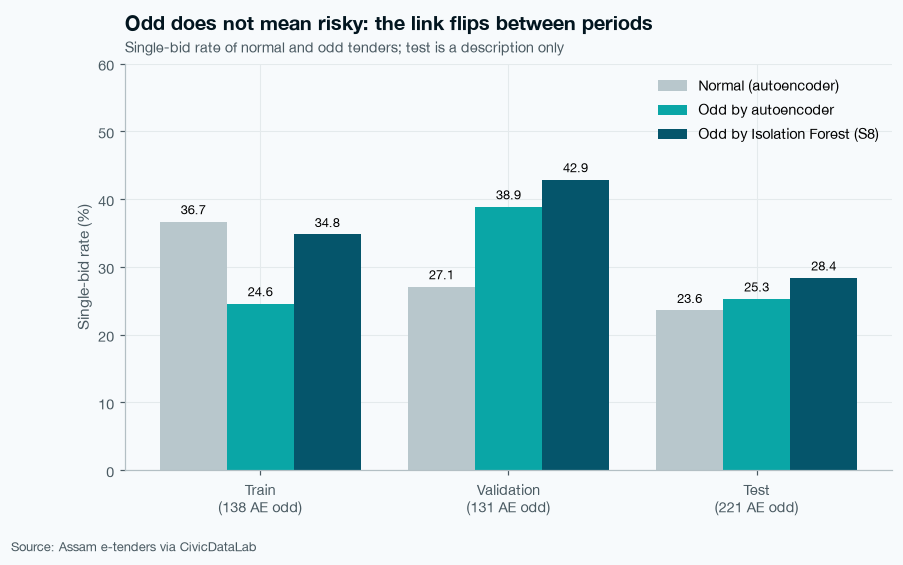

In [106]:
fig, ax = plt.subplots(figsize=(9, 4.8))  # one chart
pos = np.arange(len(rate_table))  # one position per split
b1 = ax.bar(pos - 0.27, rate_table["normal %"], width=0.27, color=ts.NEUTRAL, label="Normal (autoencoder)")  # normal
b2 = ax.bar(pos, rate_table["AE odd %"], width=0.27, color=ts.MULTI, label="Odd by autoencoder")  # AE odd
b3 = ax.bar(pos + 0.27, rate_table["IF odd %"], width=0.27, color=ts.THIRD, label="Odd by Isolation Forest (S8)")  # IF odd
ax.bar_label(b1, fmt="%.1f", padding=3, fontsize=8.5)  # labels
ax.bar_label(b2, fmt="%.1f", padding=3, fontsize=8.5)  # labels
ax.bar_label(b3, fmt="%.1f", padding=3, fontsize=8.5)  # labels
split_labels = []  # two-line split names with the number of odd tenders
for i in range(len(rate_table)):  # one label per split
    split_labels.append(["Train", "Validation", "Test"][i] + "\n(" + str(rate_table["AE odd tenders"].iloc[i]) + " AE odd)")  # label text
ax.set_xticks(pos, split_labels)  # split names
ax.set_ylim(0, 60)  # headroom
ax.set_ylabel("Single-bid rate (%)")  # y axis label
ax.legend(loc="upper right")  # legend
subtitle = "Single-bid rate of normal and odd tenders; test is a description only"  # what is measured
ts.title(ax, "Odd does not mean risky: the link flips between periods", subtitle=subtitle)  # the finding
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9o_odd_single_rate.png")  # save the chart

In [107]:
ae_all.to_csv(rep_dir + "/s9_autoencoder_scores.csv", index=False)  # save every tender's re-draw error, flag and odd clues
print("Saved autoencoder scores:", ae_all.shape)  # rows and columns

Saved autoencoder scores: (6790, 8)


### Insight · Odd clues, stability and single bids (Steps 24 and 25)

- The oddest test tender is 2023_APGCL_29273_1, a "Solar PV Plant" with an estimated value of only Rs 3,000. This is almost surely a typing mistake, and its EMD ratio looks huge because of it. The Isolation Forest also flagged it. So both detectors can catch data errors, which is useful for an auditor.
- In test, the clues that were most often one of the two odd clues were department rate (180 times) and months to financial year end (170 times). These are the clues that changed most after Sep 2022. So the autoencoder flags many new tenders simply because they look different from the old training tenders (drift), not because they are strange works. This explains why it flags 12.5% of test.
- Seed check: 3 of the 5 other seeds agreed with 83-89% of the main test flags, but 2 seeds flagged far fewer tenders (82 and 98) and agreed only 16.7%. The Isolation Forest agreed 84-93% in S8. So the autoencoder is less stable.
- Single-bid rate (normal / odd by autoencoder / odd by Isolation Forest): train 36.7 / 24.6 / 34.8, validation 27.1 / 38.9 / 42.9, test 23.6 / 25.3 / 28.4.
- In training the autoencoder's odd tenders got fewer single bids, in validation more, and in test about the same. So odd does not mean risky, and the link flips between periods. The Isolation Forest stays my anomaly signal for the app, because it is more stable and gives the same kind of "which clue is odd" reason.

## Part F · Close

### Step 26 · App decision: does the ANN replace LogReg?

I set the rule before building this section: the ANN replaces LogReg in the app only if it clearly wins. Otherwise LogReg stays, because it is simpler and SHAP explains it cleanly.

For me "clearly wins" means all three of these are true:

1. The ANN beats LogReg in 95% or more of the bootstrap re-draws.
2. The ANN beats random checking in 95% or more of the re-draws. An app model must at least beat checking tenders by chance. Beating LogReg alone is not enough, because LogReg itself was below random on validation.
3. Every seed stays above the random average, so the result is not just the luck of one starting point.

Here I check the rule with the real numbers.

In [108]:
ann_vs_lr = boot_table.loc[boot_table["comparison"] == "ANN vs LogReg", "A wins (% of draws)"].iloc[0]  # bootstrap win rate
ann_vs_random = boot_table.loc[boot_table["comparison"] == "ANN vs Random", "A wins (% of draws)"].iloc[0]  # bootstrap win rate vs random
decision = {}  # the decision table, key by key
decision["ANN PR-AUC higher than LogReg on validation"] = str(ann_pr > lr_pr) + " (" + str(ann_pr) + " vs " + str(lr_pr) + ")"  # check 1
decision["ANN beats LogReg in 95%+ of re-draws"] = str(ann_vs_lr >= 95) + " (" + str(ann_vs_lr) + "%)"  # check 2
decision["ANN beats random in 95%+ of re-draws"] = str(ann_vs_random >= 95) + " (" + str(ann_vs_random) + "%)"  # check 3
decision["All seeds above the random average"] = str(seeds_above_random == len(seed_table)) + " (" + str(seeds_above_random) + " of " + str(len(seed_table)) + ")"  # check 4
switch = (ann_vs_lr >= 95) and (ann_vs_random >= 95) and (seeds_above_random == len(seed_table))  # the rule: all three checks must be true
decision["Decision"] = "ANN replaces LogReg" if switch else "LogReg stays in the app; ANN saved as a comparison"  # result
decision_table = pd.DataFrame(list(decision.items()), columns=["check", "result"])  # as a table
decision_table  # show it

,check,result
0,ANN PR-AUC higher than LogReg on validation,True (0.286 vs 0.252)
1,ANN beats LogReg in 95%+ of re-draws,True (99.8%)
2,ANN beats random in 95%+ of re-draws,False (43.0%)
3,All seeds above the random average,False (2 of 6)
4,Decision,LogReg stays in the app; ANN saved as a compar...


### Step 27 · Save the ANN and the result files

I save the ANN either way, so I can show it or use it later. Like the S7 app model, the saved version learns from all 6,790 labelled tenders, with the layers, dropout and number of rounds I chose in Part B. It is not scored again, because it has seen every answer.

| File | What it holds |
|---|---|
| models/tenderlens_ann.keras | the ANN (Keras format) |
| models/tenderlens_ann_scaler.joblib | the scaler for its 7 clues |
| models/tenderlens_ann_settings.csv | layers, dropout and rounds |

In [109]:
scaler_app = StandardScaler()  # scaler for the saved ANN
scaler_app.fit(lab[base])  # sizes from all labelled tenders
ann_app = train_full(scaler_app.transform(lab[base]), lab["single_bid"].values, pick_sizes, pick_drop, pick_round, 42)  # ANN learned on all 6,790
ann_app.save(model_dir + "/tenderlens_ann.keras")  # save the network
joblib.dump(scaler_app, model_dir + "/tenderlens_ann_scaler.joblib")  # save its scaler

['../models/tenderlens_ann_scaler.joblib']

In [110]:
settings = {}  # the ANN settings, key by key
settings["clues"] = ", ".join(base)  # the 7 clues in order
settings["layers"] = str(pick_sizes)  # hidden layer sizes
settings["dropout"] = pick_drop  # dropout
settings["rounds"] = pick_round  # number of rounds
settings["learned from"] = "all 6,790 labelled tenders"  # data
settings["in app"] = "yes" if switch else "no (comparison only)"  # the Step 26 decision
pd.DataFrame(list(settings.items()), columns=["setting", "value"]).to_csv(model_dir + "/tenderlens_ann_settings.csv", index=False)  # save the settings

In [111]:
keep_cols = ["tender_id", "month_name", "single_bid", "risk_random", "risk_ruleb", "risk_lr", "risk_ann", "risk_team"]  # validation columns to keep, part 1
keep_cols = keep_cols + ["risk_ann34", "risk_ann_emb", "risk_ann_emb7", "band_ann", "band_lr"]  # part 2
val[keep_cols].to_csv(rep_dir + "/s9_val_predictions.csv", index=False)  # save validation scores of every method
print("Saved validation predictions:", val[keep_cols].shape)  # rows and columns

Saved validation predictions: (2270, 13)


### Step 28 · Did I miss anything? Is the ANN score a real percentage?

In S7 the LogReg scores were a ranking, not real percentages. An ANN with class weights can be even further off, because the weights push every score up. Here I split validation tenders into 5 equal groups by ANN score and compare the average score with the real single-bid rate. If the score was a true percentage, both bars would be the same height. This tells me whether the app must show bands for the ANN too.

In [112]:
group_names = ["Lowest", "Low", "Middle", "High", "Highest"]  # 5 equal groups
val["score_group"] = pd.qcut(val["risk_ann"], 5, labels=group_names)  # group by ANN score
calib = pd.DataFrame()  # empty table
calib["average ANN score %"] = val.groupby("score_group", observed=True)["risk_ann"].mean() * 100  # average score
calib["real single-bid %"] = val.groupby("score_group", observed=True)["single_bid"].mean() * 100  # real rate
calib = calib.round(1)  # one decimal
calib  # show it

,average ANN score %,real single-bid %
score_group,,
Lowest,37.200001,36.8
Low,47.599998,26.4
Middle,51.299999,16.6
High,53.400002,26.9
Highest,57.000000,31.7


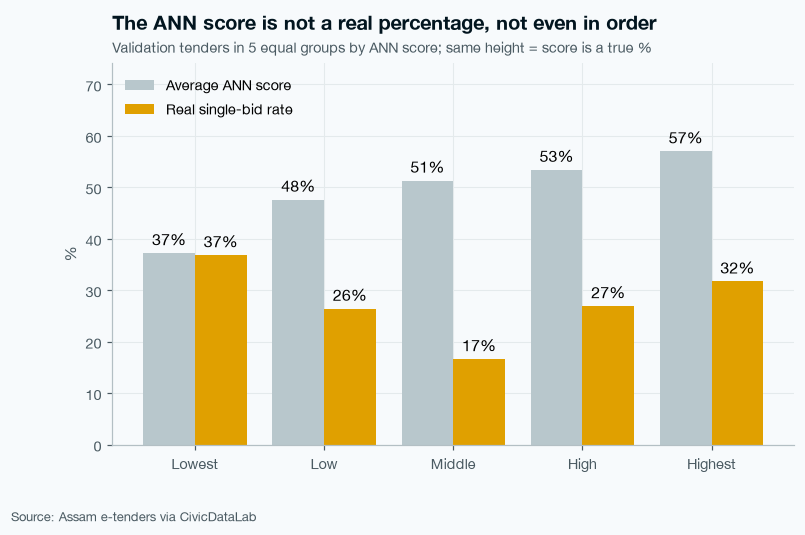

In [113]:
fig, ax = plt.subplots(figsize=(8, 4.5))  # one chart
pos = np.arange(len(calib))  # one position per group
b1 = ax.bar(pos - 0.2, calib["average ANN score %"], width=0.4, color=ts.NEUTRAL, label="Average ANN score")  # scores
b2 = ax.bar(pos + 0.2, calib["real single-bid %"], width=0.4, color=ts.SINGLE, label="Real single-bid rate")  # real rate
ax.bar_label(b1, fmt="%.0f%%", padding=3)  # labels
ax.bar_label(b2, fmt="%.0f%%", padding=3)  # labels
ax.set_xticks(pos, group_names)  # group names
ax.set_ylabel("%")  # y axis label
ax.set_ylim(0, max(calib.max().max() * 1.3, 60))  # headroom
ax.legend(loc="upper left")  # legend
subtitle = "Validation tenders in 5 equal groups by ANN score; same height = score is a true %"  # what is measured
ts.title(ax, "The ANN score is not a real percentage, not even in order", subtitle=subtitle)  # the finding
ts.source(fig)  # data source line
ts.save_fig(fig, fig_dir + "/S9p_score_vs_real.png")  # save the chart

### Insight · App decision and score check (Steps 26 to 28)

- My rule for switching was: the ANN must beat LogReg in 95%+ of re-draws, beat random checking in 95%+ of re-draws, and stay above random for every seed.
- The ANN passed only the first check (99.8%). It failed against random (43.0%) and only 2 of 6 seeds were above random. So LogReg stays in the app. The ANN is saved in models/ as a comparison (learned on all 6,790 tenders).
- This is also the explainable choice: LogReg has 8 numbers and clean SHAP reasons, while the ANN has 801 numbers and needed permutation importance to explain it.
- The ANN score is not a real percentage. Its 5 score groups had average scores from 37% to 57%, but the real single-bid rates were 36.8, 26.4, 16.6, 26.9 and 31.7. They are not even in order. So if I ever showed the ANN, I would also have to show bands, not percentages.

### Step 29 · Files saved in this section

Here I check that every file from this section was really saved.

In [114]:
saved = ["s9_size_try.csv", "s9_seed_check.csv", "s9_bootstrap.csv", "s9_month_table.csv", "s9_auditor_view.csv"]  # tables, part 1
saved = saved + ["s9_risk_bands.csv", "s9_overlap.csv", "s9_permutation.csv", "s9_val_results.csv"]  # part 2
saved = saved + ["s9_test_description.csv", "s9_autoencoder_overlap.csv", "s9_autoencoder_scores.csv", "s9_val_predictions.csv"]  # part 3
for name in saved:  # check each table
    print(os.path.exists(rep_dir + "/" + name), name)  # True means saved
model_files = ["tenderlens_ann.keras", "tenderlens_ann_scaler.joblib", "tenderlens_ann_settings.csv"]  # model files
for name in model_files:  # check each model file
    print(os.path.exists(model_dir + "/" + name), name)  # True means saved
s9_count = 0  # counter for S9 charts
for name in sorted(os.listdir(fig_dir)):  # look at each chart file
    if name.startswith("S9"):  # only S9 charts
        s9_count = s9_count + 1  # count it
print("S9 charts saved:", s9_count)  # should be 16

True s9_size_try.csv
True s9_seed_check.csv
True s9_bootstrap.csv
True s9_month_table.csv
True s9_auditor_view.csv
True s9_risk_bands.csv
True s9_overlap.csv
True s9_permutation.csv
True s9_val_results.csv
True s9_test_description.csv
True s9_autoencoder_overlap.csv
True s9_autoencoder_scores.csv
True s9_val_predictions.csv
True tenderlens_ann.keras
True tenderlens_ann_scaler.joblib
True tenderlens_ann_settings.csv
S9 charts saved: 16


## S9 Summary

Starting point
- After S7 my main model was LogReg on 7 clues with a small but real win over random on test (95.8% of re-draws). S8 added the money view and the Isolation Forest.
- My proposal promised an ANN, so S9 asked one honest question: does a smarter learner beat the simple checklist, Rule B and random checking, or does the drift after Sep 2022 beat it too?
- Test answers were already opened in S7, so every test number here is a description, not a new fair test.

What I did
- Cut training into a learn part (to Jun 2022) and a stop signal part (Jul-Sep 2022), so the network could learn when to stop without touching validation. I gave the stop signal tenders the same class weights, so both mistake scores were measured the same way.
- Built a small ANN (7 -> 16 -> 8 -> 1) step by step, with class weights and early stopping, and drew its learning curve.
- Tried four sizes (small, medium, with and without dropout) and chose one using only the stop signal part. Then retrained it on all training months.
- Raced it on validation against random checking, Rule B and LogReg, with PR-AUC, capture, lift, precision at 50/100/200 and rupees found.
- Checked 6 random starting points, a team-up of ANN and LogReg, the bootstrap, month by month, ranking inside each month, risk bands, how much the two models' lists overlap, and which clues the ANN leans on (permutation importance).
- Tried an ANN with all 34 clues, and (the optional step) ANNs on the MiniLM text embeddings, alone and with the 7 clues.
- Scored the ANN learned once on the test months, only as a description.
- Built a short autoencoder on the 10 Isolation Forest clues and compared its odd tenders with S8.
- Applied my app rule, saved the ANN files, and checked whether the ANN score is a real percentage.

What I found
- The stop signal mistake score stayed at about 0.69, the level of pure guessing, for every network size. Patterns learned up to Jun 2022 barely carried over to Jul-Sep 2022.
- On validation the ANN got PR-AUC 0.286, level with random checking (0.288) and above LogReg (0.252) and Rule B (0.268).
- It beat LogReg in 99.8% of re-draws, but random in only 43.0%. LogReg was below random on validation, so beating it is not a real win.
- The ANN wobbled a lot with the starting point (0.231 to 0.293). Only 2 of 6 seeds beat the random average.
- It found 144 single-bid tenders in the riskiest 20% vs 125 for random, but ranked inside each month it was 127 vs 126. It also found much less money (Rs 106 crore vs Rs 233 crore for random).
- ANN risk bands were flat (High 28.0, Medium 27.0, Low 28.1), so they would not guide an auditor.
- The ANN and LogReg picked very different tenders (only 84 of 454 shared). The ANN leaned most on tender value. Department rate and days to submit bids pointed the wrong way on validation.
- More clues did not help (34 clues 0.256). The text ANNs (0.274 and 0.264) did not beat random or the simple S6 LogReg on embeddings (0.300).
- On test the ANN equalled random checking (0.232, 78 found vs 79). LogReg learned once got 0.258 (102 found), the same as S7.
- The autoencoder agrees with the Isolation Forest on how it ranks tenders (rank match 0.82 on test), but it flags three times more test tenders, mostly because drift makes new tenders look odd. It is less stable across seeds, and odd does not mean risky.
- The ANN score is not a real percentage, not even in the right order.

Decision
- LogReg stays as the app model. It is simpler, explainable with SHAP, and it held up on test. The ANN is saved as a comparison. The Isolation Forest stays as the anomaly signal.
- My recruiter answer: "I built an ANN and only switched if it earned it. It was no better than random checking once I tested it fairly, so I kept the simpler, explainable model. Complexity has to earn its place."
- More years of labelled data could help a network, but drift means older data is less useful, so I would not expect a big jump.

Files saved
- Reports: s9_size_try, s9_seed_check, s9_bootstrap, s9_month_table, s9_auditor_view, s9_risk_bands, s9_overlap, s9_permutation, s9_val_results, s9_test_description, s9_autoencoder_overlap, s9_autoencoder_scores, s9_val_predictions (all .csv).
- Models: tenderlens_ann.keras, tenderlens_ann_scaler.joblib, tenderlens_ann_settings.csv.
- Charts: S9a to S9p (16).

Next steps
- S10: build the Streamlit app with LogReg (bands ranked inside each month, SHAP reasons), the Isolation Forest unusual flag with its two odd clues, the "check first" page and the GenAI review brief, then push to GitHub and deploy.
- S11: final report, README and slides. Slide idea from S9: "A smarter model is not always a better model", with the validation race chart (S9c) or the seed check chart (S9d).